# Part 1–2 (from Pt_1_2.ipynb)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load the dataset
df = pd.read_csv('og dataset.csv')

# keep an untouched original copy
df_original = df.copy()

# create a copy to be cleaned
df_clean = df.copy()

# print num of (rows,cols)
print("Dataset shape:", df_clean.shape) 
# show first 5 rows of df
df_clean.head() 

Dataset shape: (1254, 28)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
0,1166,1185,2258648,2258662,123,33,17,15858,116.0,143.0,...,0.5758,0.8235,0.0,2.0899,1.2787,1.1461,-0.2632,0.0072,0.4399,Z_Scratch
1,7,19,21512,21518,56,13,6,6632,108.0,132.0,...,0.9231,1.0000,0.0,1.7482,1.0792,0.7782,-0.5000,-0.0748,0.1773,Z_Scratch
2,37,53,50442,50467,226,33,31,25563,100.0,132.0,...,0.4848,0.8065,1.0,2.3541,1.2041,1.3979,0.3600,-0.1163,0.6574,Z_Scratch
3,39,51,66522,66578,436,41,56,39043,71.0,117.0,...,0.2927,1.0000,1.0,2.6395,1.0792,1.7482,0.7857,-0.3004,0.9216,Z_Scratch
4,193,205,82308,82319,84,19,11,9155,99.0,118.0,...,0.6316,1.0000,0.0,1.9243,1.0792,1.0414,-0.0833,-0.1485,0.2432,Z_Scratch


In [3]:
# Store all input columns except the target column, Faults
input_cols = df_clean.columns.drop('Faults').tolist()

# Display the number of input columns
print("Number of input columns:", len(input_cols))

# Display information about the entire dataset
df_clean.info()

Number of input columns: 27
<class 'pandas.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1254 non-null   int64  
 1   X_Maximum              1254 non-null   int64  
 2   Y_Minimum              1254 non-null   int64  
 3   Y_Maximum              1254 non-null   int64  
 4   Pixels_Areas           1254 non-null   int64  
 5   X_Perimeter            1254 non-null   int64  
 6   Y_Perimeter            1254 non-null   int64  
 7   Sum_of_Luminosity      1254 non-null   int64  
 8   Minimum_of_Luminosity  1129 non-null   float64
 9   Maximum_of_Luminosity  1154 non-null   float64
 10  Length_of_Conveyer     1254 non-null   int64  
 11  TypeOfSteel_A300       1254 non-null   int64  
 12  TypeOfSteel_A400       1254 non-null   int64  
 13  Steel_Plate_Thickness  1254 non-null   int64  
 14  Edges_Index            1254 non-null   

In [4]:
# Count missing values in all input columns
missing_values = df_clean[input_cols].isnull().sum()

# Display only columns that contain missing values
missing_columns = missing_values[missing_values > 0]

display(
    missing_columns.to_frame(
        name='Missing Values'
    )
)

,Missing Values
Minimum_of_Luminosity,125
Maximum_of_Luminosity,100


In [5]:
# Columns containing missing values
luminosity_cols = [
    'Minimum_of_Luminosity',
    'Maximum_of_Luminosity'
]

# Count missing values in each fault class
missing_by_class = (
    df_clean
    .groupby('Faults')[luminosity_cols]
    .apply(lambda group: group.isnull().sum())
)

display(missing_by_class)

,Minimum_of_Luminosity,Maximum_of_Luminosity
Faults,,
K_Scatch,45,29
Other_Faults,60,54
Z_Scratch,20,17


In [6]:
# Calculate distribution statistics within each fault class
distribution_summary = (
    df_clean
    .groupby('Faults')[luminosity_cols]
    .agg(['count', 'mean', 'median', 'std', 'skew'])
)

display(distribution_summary)

Minimum_of_Luminosity                                         \
                             count       mean median        std      skew   
Faults                                                                      
K_Scatch                       346  54.728324   41.0  39.143973  1.844439   
Other_Faults                   613  94.199021   97.0  29.093823 -0.205505   
Z_Scratch                      170  90.500000   93.0  19.326914 -1.114384   

             Maximum_of_Luminosity                                          
                             count        mean median        std      skew  
Faults                                                                      
K_Scatch                       362  136.701657  134.0  19.248756  2.247078  
Other_Faults                   619  129.600969  127.0  22.468116  1.083293  
Z_Scratch                      173  119.843931  124.0  15.860362 -1.159799

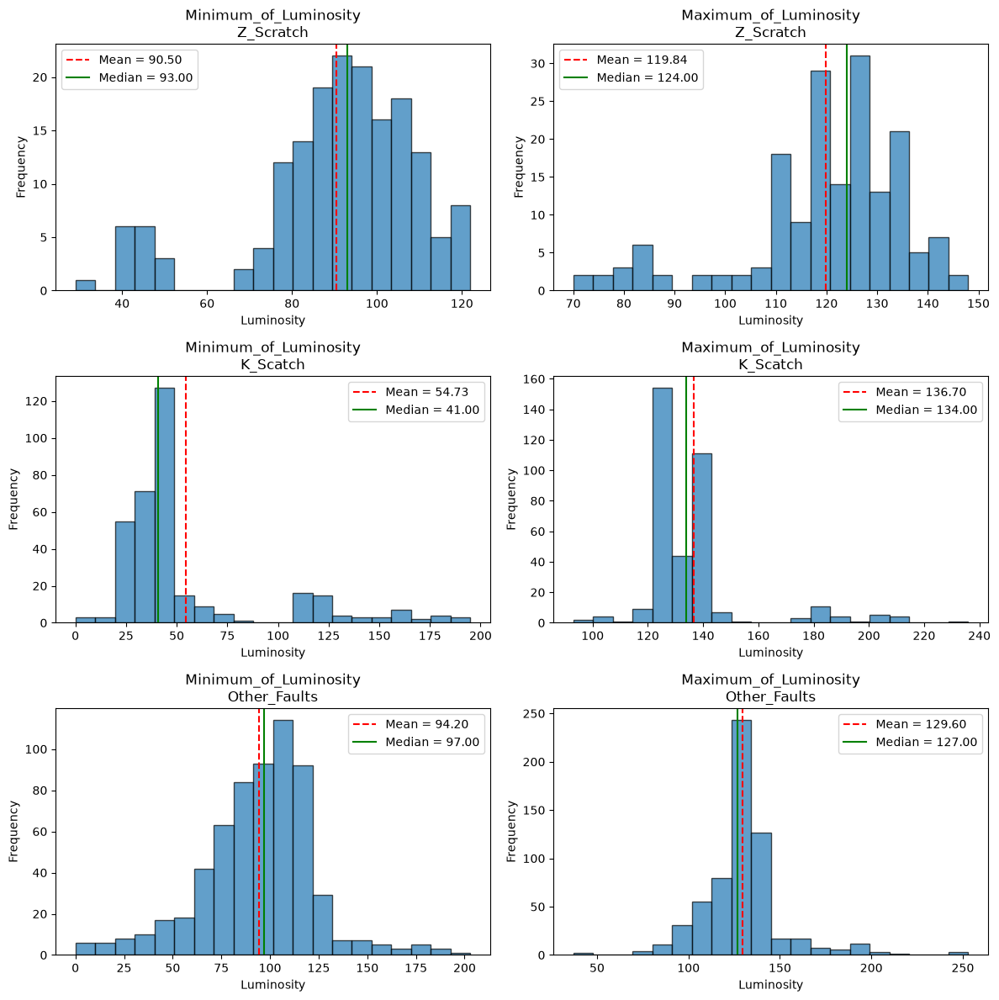

In [7]:
# Obtain the three fault classes
fault_classes = df_clean['Faults'].unique()

# Create one row of graphs for each fault class
fig, axes = plt.subplots(
    nrows=len(fault_classes), # Creates 3 rows
    ncols=2, # 2 cols for each luminosity variable
    figsize=(12, 12) # 12 inches tall & wide
)

for row, fault_class in enumerate(fault_classes):
    
    # Select rows belonging to the current fault class
    class_data = df_clean[
        df_clean['Faults'] == fault_class
    ]
    
    for column, luminosity_column in enumerate(luminosity_cols):

        # Select the current luminosity column from the current fault class
        # .dropna used since it temporarily removes missing values
        values = class_data[luminosity_column].dropna()
        
        # Plot the distribution
        axes[row, column].hist(
            values,
            bins=20, # Divide values into 20 bars
            edgecolor='black', # Black outline around each bar
            alpha=0.7 # Make the bars slightly transparent
        )
        
        # Show the class mean
        # .axvline draws a vertical line
        axes[row, column].axvline(
            values.mean(),
            color='red', # Line color = red
            linestyle='--', # Dashed line
            label=f'Mean = {values.mean():.2f}' # Text shown in legend
        )
        
        # Show the class median
        # .axvline draws a vertical line
        axes[row, column].axvline(
            values.median(),
            color='green', # Line color = green
            linestyle='-', # Solid line
            label=f'Median = {values.median():.2f}' # Text shown in legend
        )
        
        axes[row, column].set_title(
            f'{luminosity_column}\n{fault_class}'
        )
        
        axes[row, column].set_xlabel('Luminosity')
        axes[row, column].set_ylabel('Frequency')
        axes[row, column].legend()

plt.tight_layout()
plt.show()

In [8]:
# Save which cells were originally missing
# We will need this later when validating the filled values
missing_before_fill = df_clean[
    ['Minimum_of_Luminosity', 'Maximum_of_Luminosity']
].isnull().copy()


# State which method should be used for each fault class
imputation_plan = {
    'Z_Scratch': {
        'Minimum_of_Luminosity': 'median',
        'Maximum_of_Luminosity': 'median'
    },
    
    'K_Scatch': {
        'Minimum_of_Luminosity': 'median',
        'Maximum_of_Luminosity': 'median'
    },
    
    'Other_Faults': {
        'Minimum_of_Luminosity': 'mean',
        'Maximum_of_Luminosity': 'median'
    }
}


# Go through each fault class
for fault_class, column_methods in imputation_plan.items():
    
    # Go through both luminosity columns
    for column, method in column_methods.items():
        
        # Select the values from the current fault class
        class_values = df_clean.loc[
            df_clean['Faults'] == fault_class,
            column
        ]
        
        # Calculate either the class mean or class median
        if method == 'mean':
            replacement_value = class_values.mean()
        else:
            replacement_value = class_values.median()
        
        # Identify missing cells from this class and column
        missing_rows = (
            (df_clean['Faults'] == fault_class) &
            (df_clean[column].isnull())
        )
        
        # Count the number of values being filled
        number_filled = missing_rows.sum()
        
        # Fill only those missing cells
        df_clean.loc[
            missing_rows,
            column
        ] = replacement_value
        
        print(
            f"{fault_class} | {column} | "
            f"{method} = {replacement_value:.2f} | "
            f"{number_filled} values filled"
        )

Z_Scratch | Minimum_of_Luminosity | median = 93.00 | 20 values filled
Z_Scratch | Maximum_of_Luminosity | median = 124.00 | 17 values filled
K_Scatch | Minimum_of_Luminosity | median = 41.00 | 45 values filled
K_Scatch | Maximum_of_Luminosity | median = 134.00 | 29 values filled
Other_Faults | Minimum_of_Luminosity | mean = 94.20 | 60 values filled
Other_Faults | Maximum_of_Luminosity | median = 127.00 | 54 values filled


In [9]:
# Check whether any missing luminosity values remain
remaining_missing = df_clean[
    ['Minimum_of_Luminosity', 'Maximum_of_Luminosity']
].isnull().sum()

display(
    remaining_missing.to_frame(
        name='Remaining Missing Values'
    )
)

,Remaining Missing Values
Minimum_of_Luminosity,0
Maximum_of_Luminosity,0


In [10]:
# Identify rows where minimum luminosity exceeds maximum luminosity
invalid_luminosity = (
    df_clean['Minimum_of_Luminosity'] >
    df_clean['Maximum_of_Luminosity']
)

print(
    "Rows where minimum luminosity exceeds maximum:",
    invalid_luminosity.sum()
)

# Display the problematic rows
invalid_details = df_clean.loc[
    invalid_luminosity,
    [
        'Faults',
        'Minimum_of_Luminosity',
        'Maximum_of_Luminosity'
    ]
].copy()

# Show which value was originally missing and therefore imputed
invalid_details['Minimum_Was_Imputed'] = (
    missing_before_fill.loc[
        invalid_luminosity,
        'Minimum_of_Luminosity'
    ]
)

invalid_details['Maximum_Was_Imputed'] = (
    missing_before_fill.loc[
        invalid_luminosity,
        'Maximum_of_Luminosity'
    ]
)

display(invalid_details)

Rows where minimum luminosity exceeds maximum: 11


,Faults,Minimum_of_Luminosity,Maximum_of_Luminosity,Minimum_Was_Imputed,Maximum_Was_Imputed
23,Z_Scratch,93.000000,84.0,True,False
31,Z_Scratch,93.000000,84.0,True,False
101,Z_Scratch,93.000000,84.0,True,False
204,K_Scatch,178.000000,134.0,False,True
211,K_Scatch,141.000000,134.0,False,True
212,K_Scatch,139.000000,134.0,False,True
691,Other_Faults,130.000000,127.0,False,True
734,Other_Faults,132.000000,127.0,False,True
1154,Other_Faults,192.000000,127.0,False,True
1157,Other_Faults,153.000000,127.0,False,True


In [11]:
# Correct only the conflicting imputed luminosity values
for index in df_clean.index[invalid_luminosity]:
    
    fault_class = df_clean.at[index, 'Faults']
    
    # Case 1: Minimum luminosity was originally missing
    if missing_before_fill.at[index, 'Minimum_of_Luminosity']:
        
        known_maximum = df_clean.at[
            index,
            'Maximum_of_Luminosity'
        ]
        
        # Select real values from the same fault class
        # where minimum luminosity does not exceed this row's maximum
        valid_candidates = df_original.loc[
            (df_original['Faults'] == fault_class) &
            (df_original['Minimum_of_Luminosity'].notnull()) &
            (
                df_original['Minimum_of_Luminosity']
                <= known_maximum
            ),
            'Minimum_of_Luminosity'
        ]
        
        # Other_Faults uses mean; the other classes use median
        if fault_class == 'Other_Faults':
            replacement_value = valid_candidates.mean()
        else:
            replacement_value = valid_candidates.median()
        
        df_clean.at[
            index,
            'Minimum_of_Luminosity'
        ] = replacement_value
    
    
    # Case 2: Maximum luminosity was originally missing
    elif missing_before_fill.at[index, 'Maximum_of_Luminosity']:
        
        known_minimum = df_clean.at[
            index,
            'Minimum_of_Luminosity'
        ]
        
        # Select real values from the same fault class
        # where maximum luminosity is at least this row's minimum
        valid_candidates = df_original.loc[
            (df_original['Faults'] == fault_class) &
            (df_original['Maximum_of_Luminosity'].notnull()) &
            (
                df_original['Maximum_of_Luminosity']
                >= known_minimum
            ),
            'Maximum_of_Luminosity'
        ]
        
        # All maximum-luminosity distributions use the median
        replacement_value = valid_candidates.median()
        
        df_clean.at[
            index,
            'Maximum_of_Luminosity'
        ] = replacement_value

In [12]:
# Check for remaining logical conflicts
remaining_conflicts = (
    df_clean['Minimum_of_Luminosity'] >
    df_clean['Maximum_of_Luminosity']
)

print(
    "Remaining luminosity conflicts:",
    remaining_conflicts.sum()
)

# Check for remaining missing values
print(
    df_clean[
        ['Minimum_of_Luminosity', 'Maximum_of_Luminosity']
    ].isnull().sum()
)

Remaining luminosity conflicts: 0
Minimum_of_Luminosity    0
Maximum_of_Luminosity    0
dtype: int64


In [13]:
# Check the number of completely duplicated rows
duplicate_count = df_clean.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

Number of duplicated rows: 0


In [14]:
# Store the number of formatting errors found in each input column
formatting_errors = {}

for column in input_cols:
    
    # Temporarily convert the column to numeric
    # Invalid text values would become NaN
    converted_column = pd.to_numeric(
        df_clean[column],
        errors='coerce'
    )
    
    # Count values that became NaN during conversion
    formatting_errors[column] = (
        converted_column.isnull().sum()
        - df_clean[column].isnull().sum()
    )

# Convert the results into a Series
formatting_errors = pd.Series(
    formatting_errors,
    name='Formatting Errors'
)

# Display only columns containing formatting errors
display(
    formatting_errors[
        formatting_errors > 0
    ].to_frame()
)

if formatting_errors.sum() == 0:
    print("No numerical formatting errors were found.")
else:
    print(
        "Total formatting errors:",
        formatting_errors.sum()
    )

,Formatting Errors


No numerical formatting errors were found.


In [15]:
# Check physical and logical rules
validity_checks = pd.Series({
    
    # Coordinate checks
    'X_Minimum >= X_Maximum':
        (df_clean['X_Minimum'] >= df_clean['X_Maximum']).sum(),
    
    'Y_Minimum >= Y_Maximum':
        (df_clean['Y_Minimum'] >= df_clean['Y_Maximum']).sum(),
    
    
    # Size and perimeter checks
    'Pixels_Areas <= 0':
        (df_clean['Pixels_Areas'] <= 0).sum(),
    
    'X_Perimeter <= 0':
        (df_clean['X_Perimeter'] <= 0).sum(),
    
    'Y_Perimeter <= 0':
        (df_clean['Y_Perimeter'] <= 0).sum(),
    
    
    # Luminosity checks
    'Sum_of_Luminosity < 0':
        (df_clean['Sum_of_Luminosity'] < 0).sum(),
    
    'Minimum luminosity outside 0 to 255':
        (
            ~df_clean['Minimum_of_Luminosity']
            .between(0, 255)
        ).sum(),
    
    'Maximum luminosity outside 0 to 255':
        (
            ~df_clean['Maximum_of_Luminosity']
            .between(0, 255)
        ).sum(),
    
    'Minimum luminosity > maximum luminosity':
        (
            df_clean['Minimum_of_Luminosity'] >
            df_clean['Maximum_of_Luminosity']
        ).sum(),
    
    
    # Manufacturing measurement checks
    'Length_of_Conveyer <= 0':
        (df_clean['Length_of_Conveyer'] <= 0).sum(),
    
    'Steel_Plate_Thickness <= 0':
        (df_clean['Steel_Plate_Thickness'] <= 0).sum(),
    
    
    # Steel-type encoding checks
    'Invalid TypeOfSteel_A300 value':
        (
            ~df_clean['TypeOfSteel_A300']
            .isin([0, 1])
        ).sum(),
    
    'Invalid TypeOfSteel_A400 value':
        (
            ~df_clean['TypeOfSteel_A400']
            .isin([0, 1])
        ).sum(),
    
    'Invalid steel-type combination':
        (
            (
                df_clean['TypeOfSteel_A300'] +
                df_clean['TypeOfSteel_A400']
            ) != 1
        ).sum(),
    
    
    # Check for positive or negative infinity
    'Infinite numerical values':
        np.isinf(df_clean[input_cols]).sum().sum()
})

display(
    validity_checks.to_frame(
        name='Number of Invalid Rows'
    )
)

,Number of Invalid Rows
X_Minimum >= X_Maximum,0
Y_Minimum >= Y_Maximum,0
Pixels_Areas <= 0,0
X_Perimeter <= 0,0
Y_Perimeter <= 0,0
Sum_of_Luminosity < 0,0
Minimum luminosity outside 0 to 255,0
Maximum luminosity outside 0 to 255,0
Minimum luminosity > maximum luminosity,0
Length_of_Conveyer <= 0,0


In [17]:
# Name of the cleaned dataset
cleaned_file = 'dataset3_steelplate_cleaned.csv'

# Export the cleaned dataframe without an extra index column
df_clean.to_csv(
    cleaned_file,
    index=False
)

print("Cleaned dataset saved as:", cleaned_file)

Cleaned dataset saved as: dataset3_steelplate_cleaned.csv


In [1]:
# Import pandas for working with tabular data
import pandas as pd

# Load the cleaned dataset
df_clean = pd.read_csv(
    'dataset3_steelplate_cleaned.csv'
)

# Confirm that the dataset loaded correctly
print("Dataset shape:", df_clean.shape)
df_clean.head()

Dataset shape: (1254, 28)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
0,1166,1185,2258648,2258662,123,33,17,15858,116.0,143.0,...,0.5758,0.8235,0.0,2.0899,1.2787,1.1461,-0.2632,0.0072,0.4399,Z_Scratch
1,7,19,21512,21518,56,13,6,6632,108.0,132.0,...,0.9231,1.0000,0.0,1.7482,1.0792,0.7782,-0.5000,-0.0748,0.1773,Z_Scratch
2,37,53,50442,50467,226,33,31,25563,100.0,132.0,...,0.4848,0.8065,1.0,2.3541,1.2041,1.3979,0.3600,-0.1163,0.6574,Z_Scratch
3,39,51,66522,66578,436,41,56,39043,71.0,117.0,...,0.2927,1.0000,1.0,2.6395,1.0792,1.7482,0.7857,-0.3004,0.9216,Z_Scratch
4,193,205,82308,82319,84,19,11,9155,99.0,118.0,...,0.6316,1.0000,0.0,1.9243,1.0792,1.0414,-0.0833,-0.1485,0.2432,Z_Scratch


In [2]:
# Fault classes included in this analysis
selected_faults = [
    'K_Scatch',
    'Z_Scratch',
    'Other_Faults'
]

# Keep only rows belonging to the selected fault classes
# .isin checks if each rows belongs to the selected classes
# .copy to create a seperate df without changing df_clean
df_selected = df_clean[
    df_clean['Faults'].isin(selected_faults)
].copy()

# Check the number of observations in each selected class
print("Selected dataset shape:", df_selected.shape)
# print the num of samples in selected faults
display(df_selected['Faults'].value_counts())

Selected dataset shape: (1254, 28)


Faults
Other_Faults    673
K_Scatch        391
Z_Scratch       190
Name: count, dtype: int64

In [3]:
# Select all numerical parameters
# will ignore faults col
parameter_cols = df_selected.select_dtypes(
    include='number'
).columns.tolist()

print("Number of parameters:", len(parameter_cols))
print(parameter_cols)

Number of parameters: 27
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']


In [4]:
from IPython.display import display, Markdown # Function to bold headers 

# Function for calculating range
def calculate_range(values):
    return values.max() - values.min()


# Group the data by fault class and calculate the statistics
statistics = (
    df_selected
    .groupby('Faults')[parameter_cols]
    .agg([
        'mean',
        'median',
        calculate_range,
        'std'
    ])
    .round(2) # 2 decimal places
)

# Parameters assigned to me: Columns A to AA
my_parameters = parameter_cols[14:27]

# Display each parameter as a separate table
for parameter in my_parameters:
    
    # Get the statistics for this parameter
    parameter_table = statistics[parameter].copy()
    
    # Rename the columns
    parameter_table = parameter_table.rename(columns={
        'mean': 'Mean',
        'median': 'Median',
        'calculate_range': 'Range',
        'std': 'Standard Deviation'
    })
    
    # Display the parameter name
    print(f"\n{'-' * 70}")
    
    # Bold each parameter heading
    display(Markdown(f"### **{parameter}**"))
    
    # Display the table
    display(parameter_table)


----------------------------------------------------------------------


### **Edges_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.13,0.06,0.96,0.19
Other_Faults,0.37,0.32,1.00,0.29
Z_Scratch,0.19,0.15,0.94,0.19



----------------------------------------------------------------------


### **Empty_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.46,0.46,0.94,0.13
Other_Faults,0.42,0.42,0.89,0.14
Z_Scratch,0.47,0.46,0.68,0.11



----------------------------------------------------------------------


### **Square_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.60,0.46,0.99,0.26
Other_Faults,0.54,0.53,0.99,0.28
Z_Scratch,0.57,0.58,0.94,0.24



----------------------------------------------------------------------


### **Outside_X_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.11,0.11,0.62,0.07
Other_Faults,0.02,0.01,0.87,0.05
Z_Scratch,0.01,0.01,0.10,0.01



----------------------------------------------------------------------


### **Edges_X_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.55,0.62,0.99,0.25
Other_Faults,0.64,0.65,0.92,0.24
Z_Scratch,0.51,0.50,0.92,0.21



----------------------------------------------------------------------


### **Edges_Y_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.53,0.47,0.77,0.18
Other_Faults,0.83,0.94,0.95,0.22
Z_Scratch,0.88,0.93,0.64,0.15



----------------------------------------------------------------------


### **Outside_Global_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.31,0.0,1.0,0.46
Other_Faults,0.60,1.0,1.0,0.48
Z_Scratch,0.70,1.0,1.0,0.45



----------------------------------------------------------------------


### **LogOfAreas**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,3.60,3.80,4.88,0.70
Other_Faults,2.28,2.16,3.40,0.52
Z_Scratch,2.31,2.16,2.17,0.51



----------------------------------------------------------------------


### **Log_X_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,2.04,2.19,2.64,0.42
Other_Faults,1.24,1.15,2.60,0.34
Z_Scratch,1.20,1.18,1.35,0.23



----------------------------------------------------------------------


### **Log_Y_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,1.84,1.83,4.26,0.40
Other_Faults,1.30,1.26,2.31,0.41
Z_Scratch,1.40,1.30,1.89,0.39



----------------------------------------------------------------------


### **Orientation_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,-0.30,-0.52,1.83,0.37
Other_Faults,0.11,0.18,1.94,0.53
Z_Scratch,0.26,0.35,1.70,0.42



----------------------------------------------------------------------


### **Luminosity_Index**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,-0.10,-0.16,1.59,0.17
Other_Faults,-0.12,-0.12,1.53,0.17
Z_Scratch,-0.19,-0.16,0.63,0.14



----------------------------------------------------------------------


### **SigmoidOfAreas**

,Mean,Median,Range,Standard Deviation
Faults,,,,
K_Scatch,0.92,1.00,0.88,0.23
Other_Faults,0.54,0.42,0.87,0.31
Z_Scratch,0.57,0.46,0.82,0.32


In [5]:
# Rearrange the statistical results into a vertical table
statistics_table = (
    statistics
    .stack(level=0) # take col lvl 0 (parameter) 
                    # & move it into a row index
    .reset_index()  # turn Faults & Parameter from
                    # index to ordinary cols
    .rename(columns={
        'level_1': 'Parameter',
        'mean': 'Mean',
        'median': 'Median',
        'calculate_range': 'Range',
        'std': 'Standard Deviation'
    })
)

# Arrange the columns clearly
statistics_table = statistics_table[
    [
        'Faults',
        'Parameter',
        'Mean',
        'Median',
        'Range',
        'Standard Deviation'
    ]
]

display(statistics_table)

,Faults,Parameter,Mean,Median,Range,Standard Deviation
0,K_Scatch,X_Minimum,136.59,41.00,1614.00,265.86
1,K_Scatch,X_Maximum,285.06,212.00,1629.00,236.50
2,K_Scatch,Y_Minimum,1649199.76,1512277.00,7805454.00,1484149.97
3,K_Scatch,Y_Maximum,1649336.20,1512467.00,7805487.00,1484227.19
4,K_Scatch,Pixels_Areas,7622.65,6281.00,152653.00,9100.61
...,...,...,...,...,...,...
76,Z_Scratch,Log_X_Index,1.20,1.18,1.35,0.23
77,Z_Scratch,Log_Y_Index,1.40,1.30,1.89,0.39
78,Z_Scratch,Orientation_Index,0.26,0.35,1.70,0.42
79,Z_Scratch,Luminosity_Index,-0.19,-0.16,0.63,0.14


# Part 3: All Faults Analysis (from data-analytics-project-all-faults.ipynb)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

#set pandas to display full numbers without scientific notation
pd.set_option('display.float_format', '{:.4f}'.format)

#load dataset
#load the cleaned csv saved by Part 1 (cell "Export the cleaned dataframe")
path = "dataset3_steelplate_cleaned.csv"
df = pd.read_csv(path)
print(df.shape)
print(df.columns.tolist())
display(df.head())

#create SteelType column for full dataset
df['SteelType'] = df['TypeOfSteel_A300'].apply(
    lambda x: 'A300' if x == 1 else 'A400')

#define numeric parameters excluding only non-numeric columns
params = df.drop(columns=['SteelType', 'Faults']).columns.tolist()
all_params = params

print("Parameters:", params)
print("Total parameters:", len(params))
print("\nFault Distribution:")
print(df['Faults'].value_counts())
print("\nSteel Type Distribution:")
print(df['SteelType'].value_counts())

#create separate dataframes for each fault class
df_other = df[df['Faults'] == 'Other_Faults'].copy()
df_k = df[df['Faults'] == 'K_Scatch'].copy()
df_z = df[df['Faults'] == 'Z_Scratch'].copy()

print("\nOther_Faults shape:", df_other.shape)
print("K_Scratch shape:", df_k.shape)
print("Z_Scratch shape:", df_z.shape)

(1254, 28)
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'Faults']


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Faults
0,1166,1185,2258648,2258662,123,33,17,15858,116.0000,143.0000,...,0.5758,0.8235,0.0000,2.0899,1.2787,1.1461,-0.2632,0.0072,0.4399,Z_Scratch
1,7,19,21512,21518,56,13,6,6632,108.0000,132.0000,...,0.9231,1.0000,0.0000,1.7482,1.0792,0.7782,-0.5000,-0.0748,0.1773,Z_Scratch
2,37,53,50442,50467,226,33,31,25563,100.0000,132.0000,...,0.4848,0.8065,1.0000,2.3541,1.2041,1.3979,0.3600,-0.1163,0.6574,Z_Scratch
3,39,51,66522,66578,436,41,56,39043,71.0000,117.0000,...,0.2927,1.0000,1.0000,2.6395,1.0792,1.7482,0.7857,-0.3004,0.9216,Z_Scratch
4,193,205,82308,82319,84,19,11,9155,99.0000,118.0000,...,0.6316,1.0000,0.0000,1.9243,1.0792,1.0414,-0.0833,-0.1485,0.2432,Z_Scratch


Parameters: ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']
Total parameters: 27

Fault Distribution:
Faults
Other_Faults    673
K_Scatch        391
Z_Scratch       190
Name: count, dtype: int64

Steel Type Distribution:
SteelType
A400    815
A300    439
Name: count, dtype: int64

Other_Faults shape: (673, 29)
K_Scratch shape: (391, 29)
Z_Scratch shape: (190, 29)


In [8]:
#function to calculate statistics for a given dataframe
def get_stats(data, label):
    stats = pd.DataFrame({
        'Mean': data[params].mean(),
        'Median': data[params].median(),
        'Std': data[params].std(),
        'Range': data[params].max() - data[params].min()
    }).round(4)
    print(f"\nStatistical Analysis for {label}:")
    print("="*60)
    display(stats)
    stats.to_csv(f"{label}_statistics.csv")
    print(f"Statistics saved to {label}_statistics.csv")
    return stats

#calculate statistics for each fault class
stats_other = get_stats(df_other, 'Other_Faults')
stats_k = get_stats(df_k, 'K_Scatch')
stats_z = get_stats(df_z, 'Z_Scratch')


Statistical Analysis for Other_Faults:


,Mean,Median,Std,Range
X_Minimum,688.8930,655.0000,513.5950,1705.0000
X_Maximum,717.5171,727.0000,512.8075,1709.0000
Y_Minimum,1445117.8871,880521.0000,1858041.9384,12409742.0000
Y_Maximum,1445152.1813,880535.0000,1858039.9838,12409749.0000
Pixels_Areas,584.3715,146.0000,2040.2102,37319.0000
X_Perimeter,52.7875,25.0000,96.8494,1271.0000
Y_Perimeter,43.8707,22.0000,69.5299,901.0000
Sum_of_Luminosity,61570.4889,16987.0000,212659.2050,3916383.0000
Minimum_of_Luminosity,94.1513,95.0000,27.7922,203.0000
Maximum_of_Luminosity,129.6256,127.0000,21.8389,216.0000


Statistics saved to Other_Faults_statistics.csv

Statistical Analysis for K_Scatch:


,Mean,Median,Std,Range
X_Minimum,136.5934,41.0000,265.8608,1614.0000
X_Maximum,285.0614,212.0000,236.4961,1629.0000
Y_Minimum,1649199.7570,1512277.0000,1484149.9740,7805454.0000
Y_Maximum,1649336.1995,1512467.0000,1484227.1892,7805487.0000
Pixels_Areas,7622.6547,6281.0000,9100.6074,152653.0000
X_Perimeter,384.6573,271.0000,577.1950,10447.0000
Y_Perimeter,255.3504,139.0000,922.6649,18151.0000
Sum_of_Luminosity,835433.6010,654358.0000,841604.9005,11591164.0000
Minimum_of_Luminosity,53.1483,41.0000,37.0769,195.0000
Maximum_of_Luminosity,136.6854,134.0000,18.7253,143.0000


Statistics saved to K_Scatch_statistics.csv

Statistical Analysis for Z_Scratch:


,Mean,Median,Std,Range
X_Minimum,209.3158,106.0000,312.3176,1341.0000
X_Maximum,228.0421,123.0000,311.8531,1341.0000
Y_Minimum,1309620.0158,1236179.0000,752902.8779,2930198.0000
Y_Maximum,1309661.4316,1236224.0000,752891.7412,2930189.0000
Pixels_Areas,506.5947,146.0000,1039.7946,7528.0000
X_Perimeter,56.4737,28.0000,88.7956,738.0000
Y_Perimeter,49.6737,23.0000,74.5664,530.0000
Sum_of_Luminosity,51466.1947,16102.0000,109349.4350,914791.0000
Minimum_of_Luminosity,90.5026,93.0000,18.3760,93.0000
Maximum_of_Luminosity,120.2158,124.0000,15.1769,78.0000


Statistics saved to Z_Scratch_statistics.csv


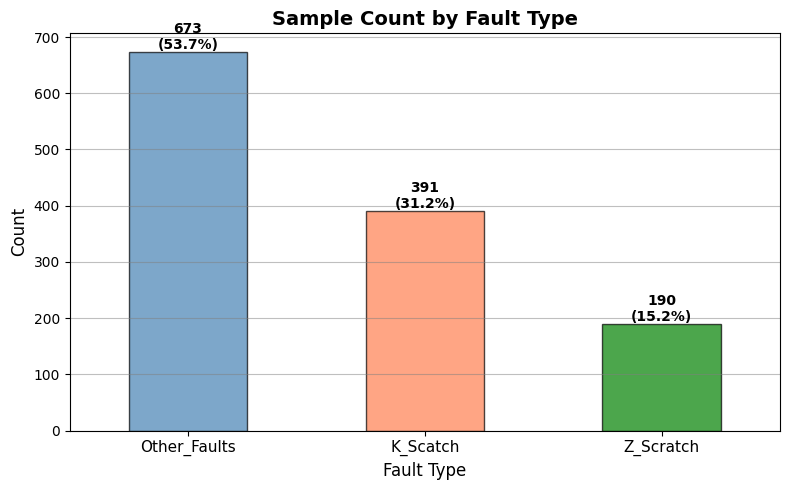

In [26]:
#bar chart showing samples per fault type with percentage
fault_counts = df['Faults'].value_counts()
fault_pct = df['Faults'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))
fault_counts.plot.bar(color=['steelblue', 'coral', 'green'],
                      edgecolor='black', alpha=0.7)

#add count and percentage on top of each bar
for i, (count, pct) in enumerate(zip(fault_counts, fault_pct)):
    plt.text(i, count + 5, f'{count}\n({pct:.1f}%)', 
             ha='center', fontsize=10, fontweight='bold')

plt.title('Sample Count by Fault Type', fontsize=14, fontweight='bold')
plt.xlabel('Fault Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='-', alpha=0.5, color='gray')
plt.tight_layout()
plt.savefig('Sample_Count_By_Fault_Type.png', dpi=300, bbox_inches='tight')
plt.show()

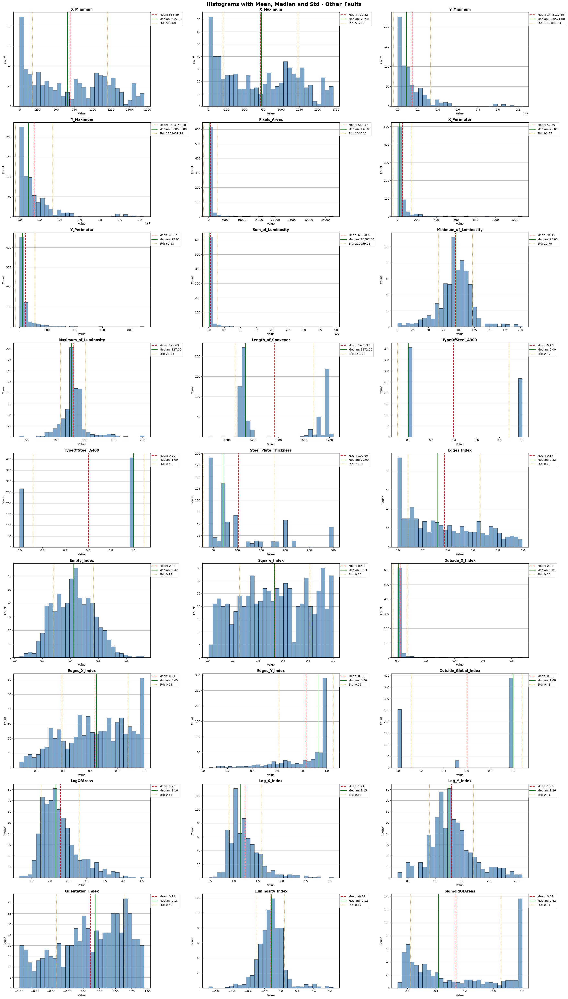

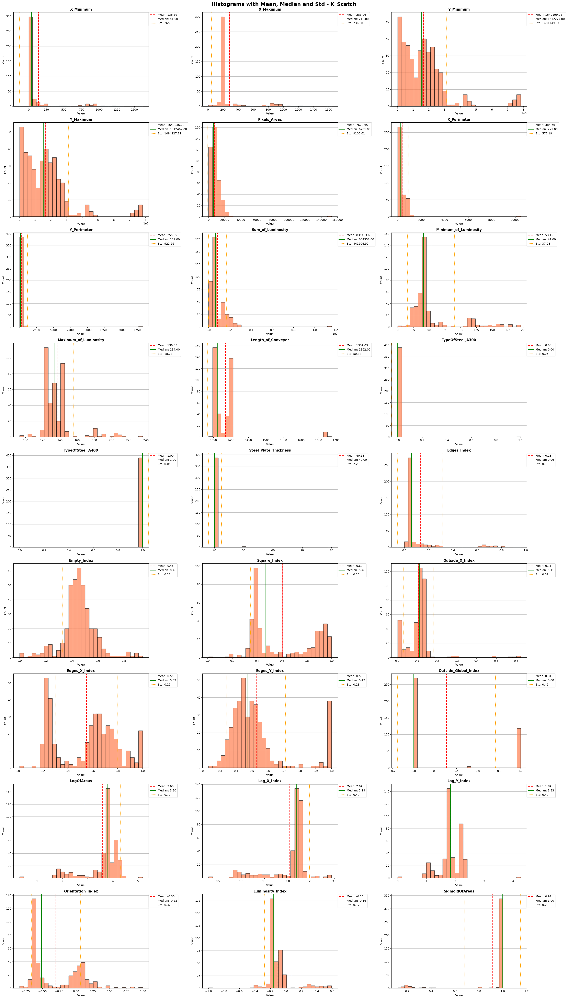

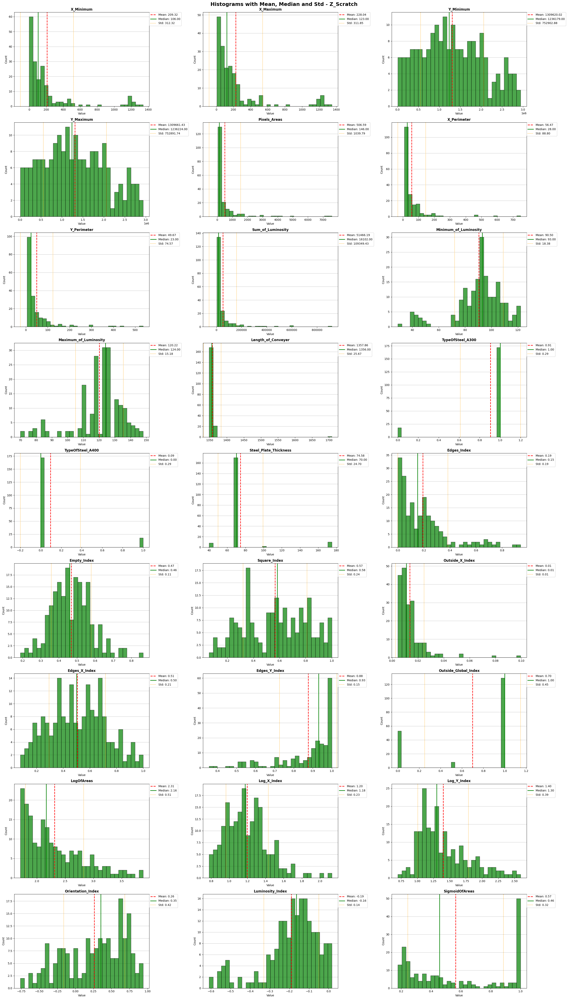

In [10]:
#function to plot histograms for a given dataframe
def plot_histograms(data, label, color='steelblue'):
    fig, axes = plt.subplots(9, 3, figsize=(28, 50))
    axes = axes.flatten()

    for i, param in enumerate(all_params):
        d = data[param].dropna()

        #plot histogram
        axes[i].hist(d, bins=30, color=color,
                     edgecolor='black', alpha=0.7)

        #add mean line in red
        axes[i].axvline(d.mean(), color='red',
                        linewidth=2, linestyle='--',
                        label=f'Mean: {d.mean():.2f}')

        #add median line in green
        axes[i].axvline(d.median(), color='green',
                        linewidth=2, linestyle='-',
                        label=f'Median: {d.median():.2f}')

        #add std lines in orange
        axes[i].axvline(d.mean() + d.std(), color='orange',
                        linewidth=1.5, linestyle=':',
                        label=f'Std: {d.std():.2f}')
        axes[i].axvline(d.mean() - d.std(), color='orange',
                        linewidth=1.5, linestyle=':')

        axes[i].set_title(param, fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Value', fontsize=10)
        axes[i].set_ylabel('Count', fontsize=10)
        axes[i].legend(fontsize=10, loc='upper left',
                       bbox_to_anchor=(1, 1), borderaxespad=0)

        #add horizontal grid lines
        axes[i].yaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
        axes[i].set_axisbelow(True)

    #hide empty subplots
    for j in range(len(all_params), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Histograms with Mean, Median and Std - {label}',
                 fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.97)

    #save figure as png
    plt.savefig(f'Histograms_{label}.png', dpi=300, bbox_inches='tight')
    plt.show()

#plot histograms for each fault class
plot_histograms(df_other, 'Other_Faults', color='steelblue')
plot_histograms(df_k, 'K_Scatch', color='coral')
plot_histograms(df_z, 'Z_Scratch', color='green')

In [15]:
#function to identify skewed parameters
def get_skewed(data, label):
    skewed = []
    for param in all_params:
        d = data[param].dropna()
        skewness = d.skew()
        if abs(skewness) > 1:
            skewed.append({
                'Parameter': param,
                'Skewness': round(skewness, 4)
            })
    df_skewed = pd.DataFrame(skewed).sort_values('Skewness', ascending=False)
    print(f"\nSkewed Parameters (|skewness| > 1) - {label}:")
    print(df_skewed.to_string())
    return df_skewed['Parameter'].tolist()

#get skewed parameters for each fault class
skewed_other = get_skewed(df_other, 'Other_Faults')
skewed_k = get_skewed(df_k, 'K_Scatch')
skewed_z = get_skewed(df_z, 'Z_Scratch')


Skewed Parameters (|skewness| > 1) - Other_Faults:
                Parameter  Skewness
5       Sum_of_Luminosity   11.5049
2            Pixels_Areas   11.4230
8         Outside_X_Index   10.7011
3             X_Perimeter    6.5896
4             Y_Perimeter    5.3212
1               Y_Maximum    3.0038
0               Y_Minimum    3.0038
11            Log_X_Index    1.6122
7   Steel_Plate_Thickness    1.3672
10             LogOfAreas    1.2064
6   Maximum_of_Luminosity    1.1565
9           Edges_Y_Index   -1.4035

Skewed Parameters (|skewness| > 1) - K_Scatch:
                Parameter  Skewness
11       TypeOfSteel_A300   19.7737
6             Y_Perimeter   18.8086
13  Steel_Plate_Thickness   15.9727
5             X_Perimeter   13.7175
4            Pixels_Areas   10.5648
7       Sum_of_Luminosity    5.7862
10     Length_of_Conveyer    4.6144
15        Outside_X_Index    3.6065
0               X_Minimum    2.9903
1               X_Maximum    2.7919
14            Edges_Index    2.7283


SECTION 1 - CORRELATION BY FAULT CLASS


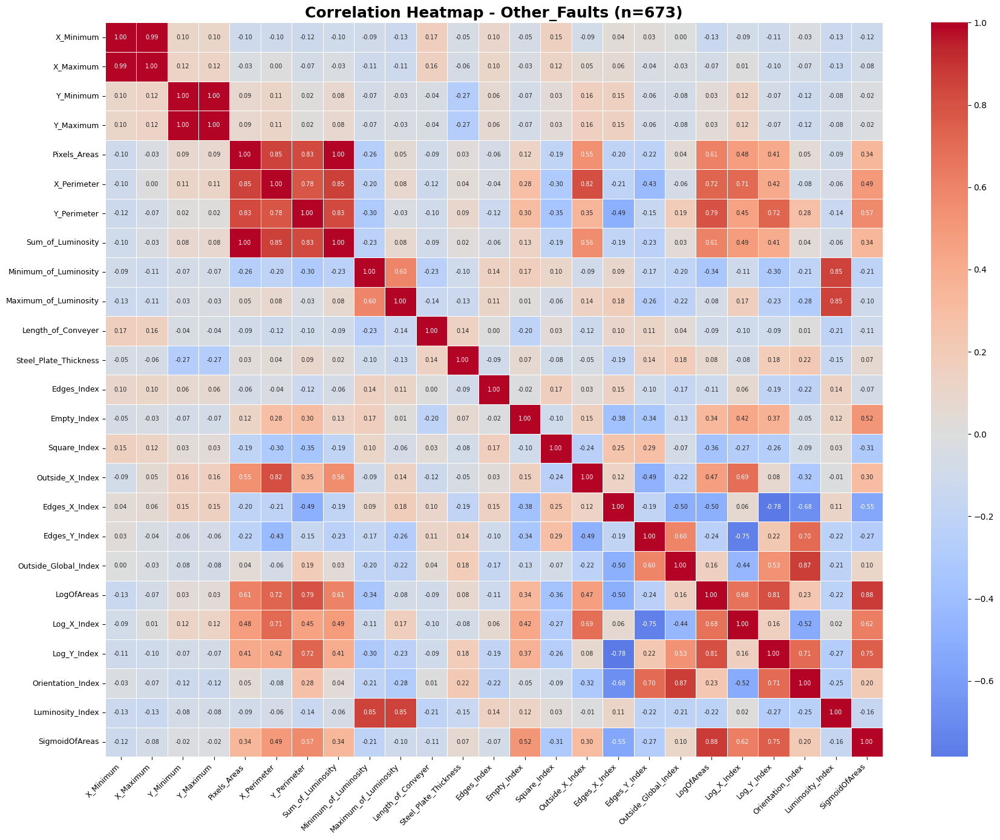


Highly correlated pairs (|r| > 0.8) - Other_Faults:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
4            Pixels_Areas  Sum_of_Luminosity       0.9969
0               X_Minimum          X_Maximum       0.9912
12             LogOfAreas     SigmoidOfAreas       0.8793
10   Outside_Global_Index  Orientation_Index       0.8708
5             X_Perimeter  Sum_of_Luminosity       0.8543
9   Maximum_of_Luminosity   Luminosity_Index       0.8499
2            Pixels_Areas        X_Perimeter       0.8493
8   Minimum_of_Luminosity   Luminosity_Index       0.8477
3            Pixels_Areas        Y_Perimeter       0.8309
7             Y_Perimeter  Sum_of_Luminosity       0.8258
6             X_Perimeter    Outside_X_Index       0.8165
11             LogOfAreas        Log_Y_Index       0.8095


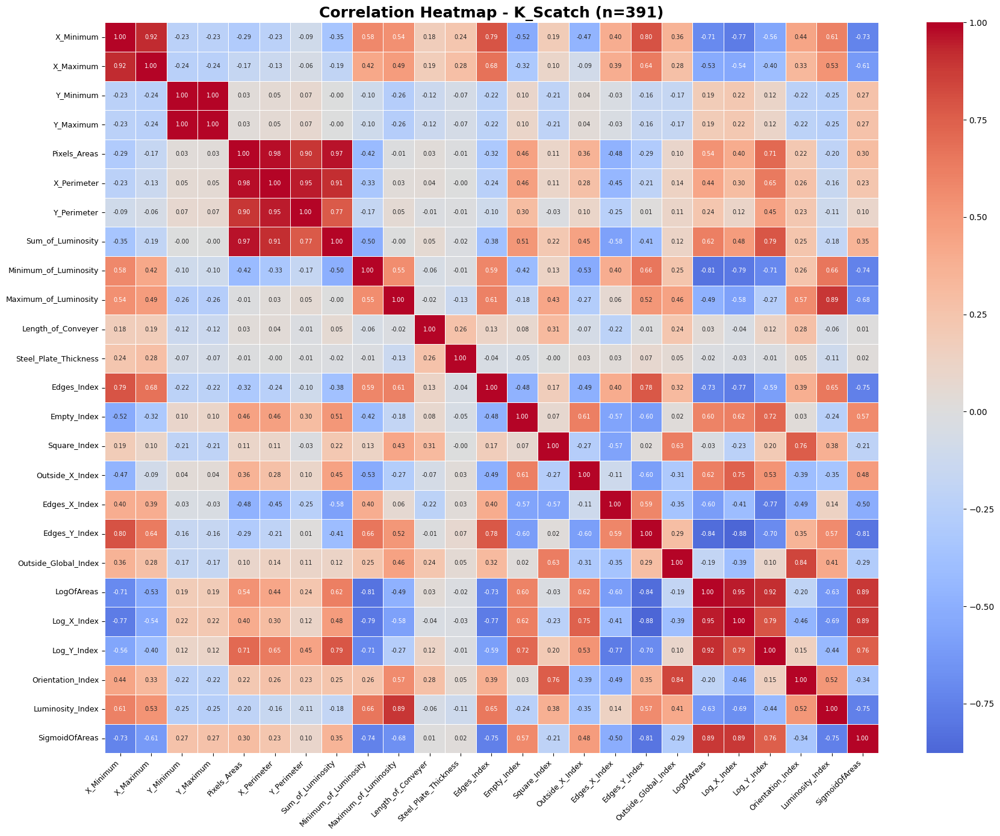


Highly correlated pairs (|r| > 0.8) - K_Scatch:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
2            Pixels_Areas        X_Perimeter       0.9766
4            Pixels_Areas  Sum_of_Luminosity       0.9706
5             X_Perimeter        Y_Perimeter       0.9533
13             LogOfAreas        Log_X_Index       0.9499
0               X_Minimum          X_Maximum       0.9225
14             LogOfAreas        Log_Y_Index       0.9186
6             X_Perimeter  Sum_of_Luminosity       0.9127
3            Pixels_Areas        Y_Perimeter       0.8957
8   Maximum_of_Luminosity   Luminosity_Index       0.8918
16            Log_X_Index     SigmoidOfAreas       0.8877
15             LogOfAreas     SigmoidOfAreas       0.8852
12   Outside_Global_Index  Orientation_Index       0.8411
11          Edges_Y_Index     SigmoidOfAreas      -0.8081
7   Minimum_of_Luminosity         LogOfAreas      -0.8139
9           Edges_Y_Ind

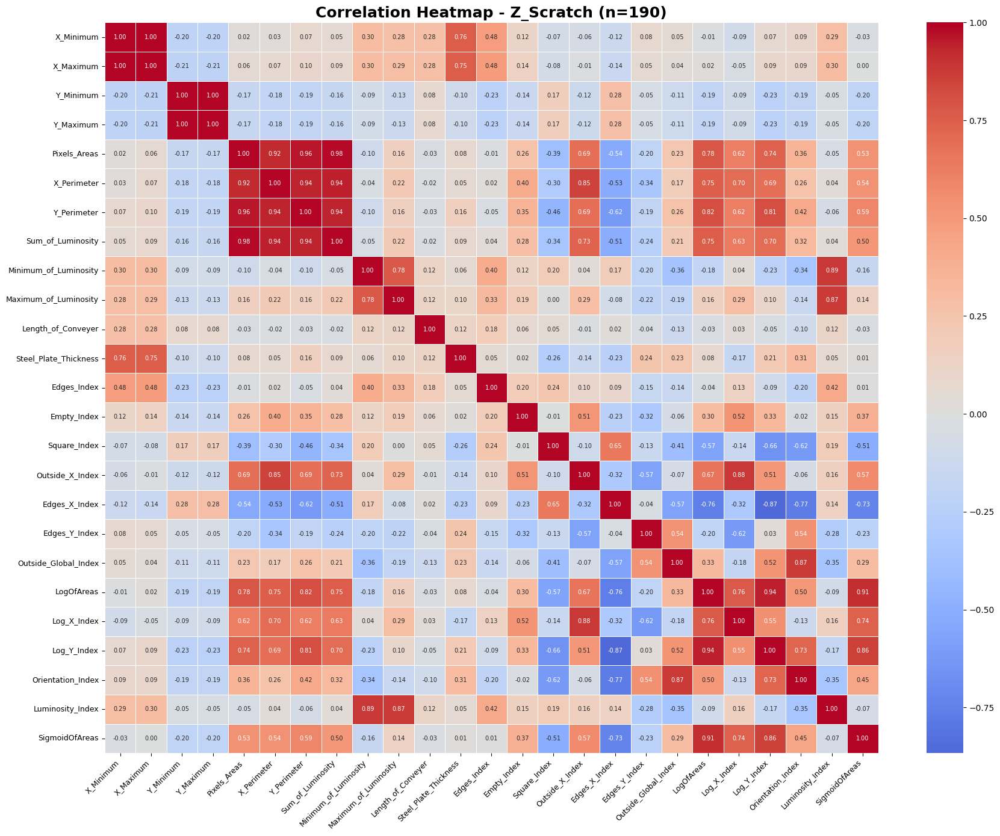


Highly correlated pairs (|r| > 0.8) - Z_Scratch:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
0               X_Minimum          X_Maximum       0.9989
4            Pixels_Areas  Sum_of_Luminosity       0.9801
3            Pixels_Areas        Y_Perimeter       0.9617
6             X_Perimeter  Sum_of_Luminosity       0.9445
16             LogOfAreas        Log_Y_Index       0.9423
8             Y_Perimeter  Sum_of_Luminosity       0.9384
5             X_Perimeter        Y_Perimeter       0.9357
2            Pixels_Areas        X_Perimeter       0.9240
17             LogOfAreas     SigmoidOfAreas       0.9141
11  Minimum_of_Luminosity   Luminosity_Index       0.8866
13        Outside_X_Index        Log_X_Index       0.8828
12  Maximum_of_Luminosity   Luminosity_Index       0.8719
15   Outside_Global_Index  Orientation_Index       0.8708
18            Log_Y_Index     SigmoidOfAreas       0.8605
7             X_Perime

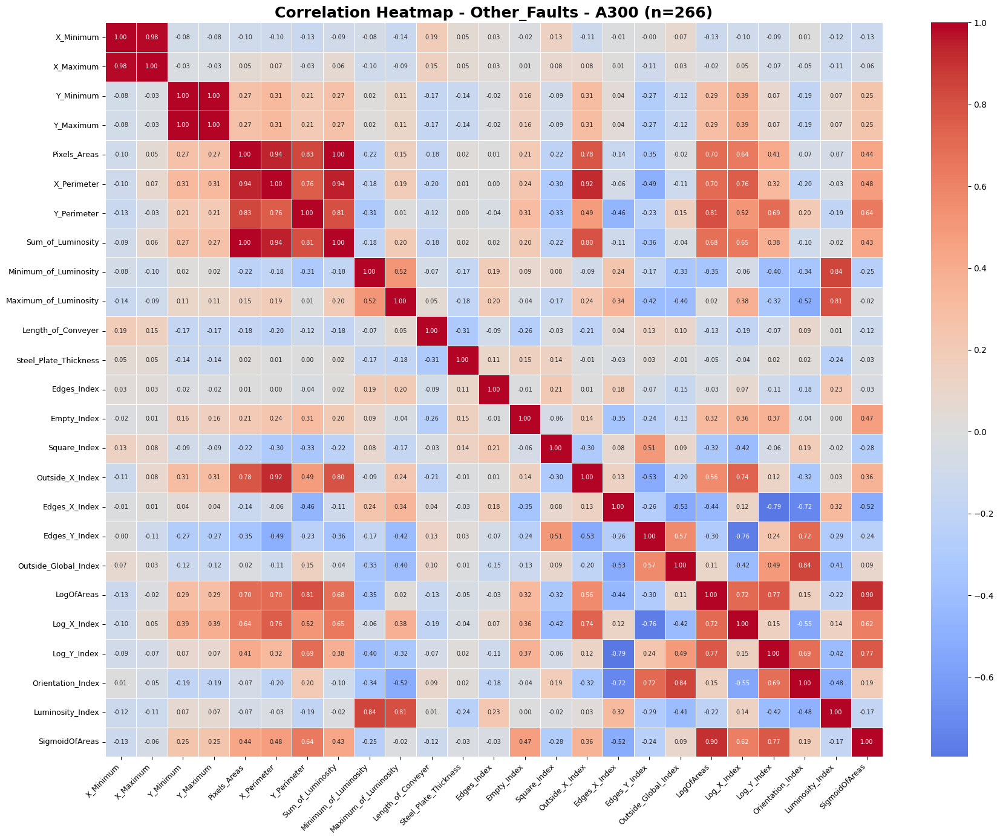


Highly correlated pairs (|r| > 0.8) - Other_Faults - A300:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
4            Pixels_Areas  Sum_of_Luminosity       0.9957
0               X_Minimum          X_Maximum       0.9815
5             X_Perimeter  Sum_of_Luminosity       0.9445
2            Pixels_Areas        X_Perimeter       0.9392
6             X_Perimeter    Outside_X_Index       0.9176
13             LogOfAreas     SigmoidOfAreas       0.9049
10  Minimum_of_Luminosity   Luminosity_Index       0.8438
12   Outside_Global_Index  Orientation_Index       0.8391
3            Pixels_Areas        Y_Perimeter       0.8348
7             Y_Perimeter  Sum_of_Luminosity       0.8102
8             Y_Perimeter         LogOfAreas       0.8081
11  Maximum_of_Luminosity   Luminosity_Index       0.8067
9       Sum_of_Luminosity    Outside_X_Index       0.8030


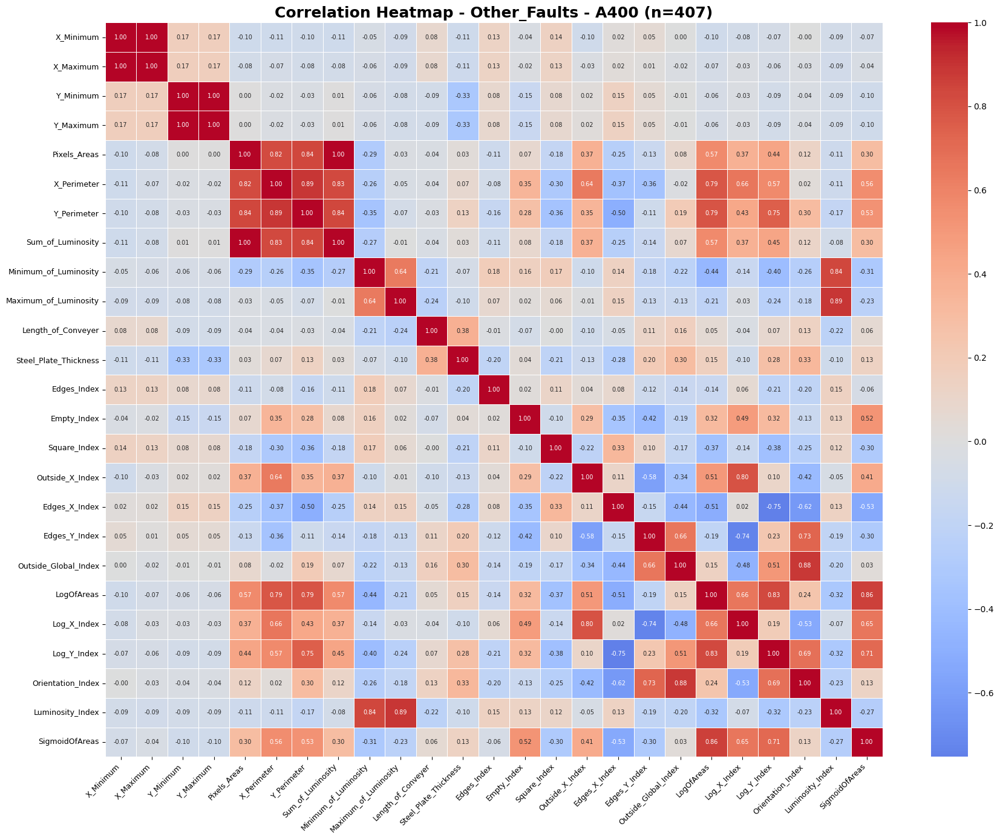


Highly correlated pairs (|r| > 0.8) - Other_Faults - A400:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
0               X_Minimum          X_Maximum       0.9978
4            Pixels_Areas  Sum_of_Luminosity       0.9977
5             X_Perimeter        Y_Perimeter       0.8941
9   Maximum_of_Luminosity   Luminosity_Index       0.8911
10   Outside_Global_Index  Orientation_Index       0.8832
12             LogOfAreas     SigmoidOfAreas       0.8563
7             Y_Perimeter  Sum_of_Luminosity       0.8407
3            Pixels_Areas        Y_Perimeter       0.8380
8   Minimum_of_Luminosity   Luminosity_Index       0.8364
11             LogOfAreas        Log_Y_Index       0.8328
6             X_Perimeter  Sum_of_Luminosity       0.8269
2            Pixels_Areas        X_Perimeter       0.8176

Skipping K_Scatch - A300: only 1 samples


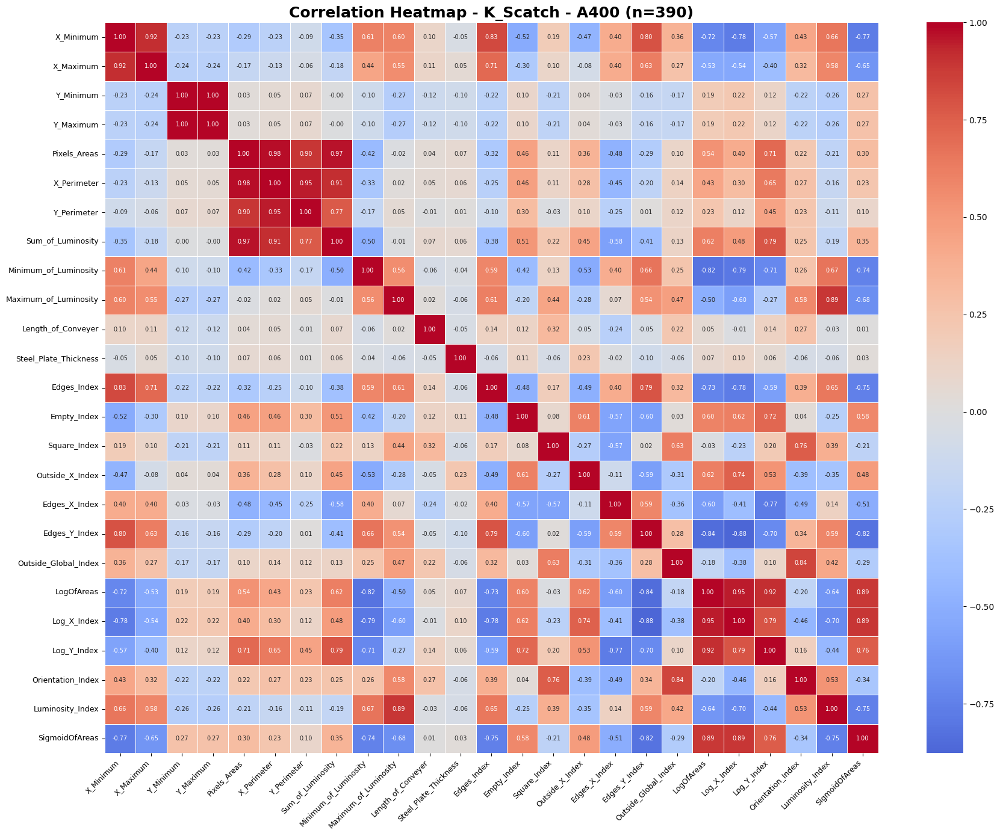


Highly correlated pairs (|r| > 0.8) - K_Scatch - A400:
                Feature 1          Feature 2  Correlation
3               Y_Minimum          Y_Maximum       1.0000
4            Pixels_Areas        X_Perimeter       0.9766
6            Pixels_Areas  Sum_of_Luminosity       0.9706
7             X_Perimeter        Y_Perimeter       0.9535
15             LogOfAreas        Log_X_Index       0.9500
16             LogOfAreas        Log_Y_Index       0.9185
0               X_Minimum          X_Maximum       0.9156
8             X_Perimeter  Sum_of_Luminosity       0.9127
5            Pixels_Areas        Y_Perimeter       0.8959
18            Log_X_Index     SigmoidOfAreas       0.8915
10  Maximum_of_Luminosity   Luminosity_Index       0.8909
17             LogOfAreas     SigmoidOfAreas       0.8873
14   Outside_Global_Index  Orientation_Index       0.8401
1               X_Minimum        Edges_Index       0.8300
2               X_Minimum      Edges_Y_Index       0.8020
9   Minimum_of_L

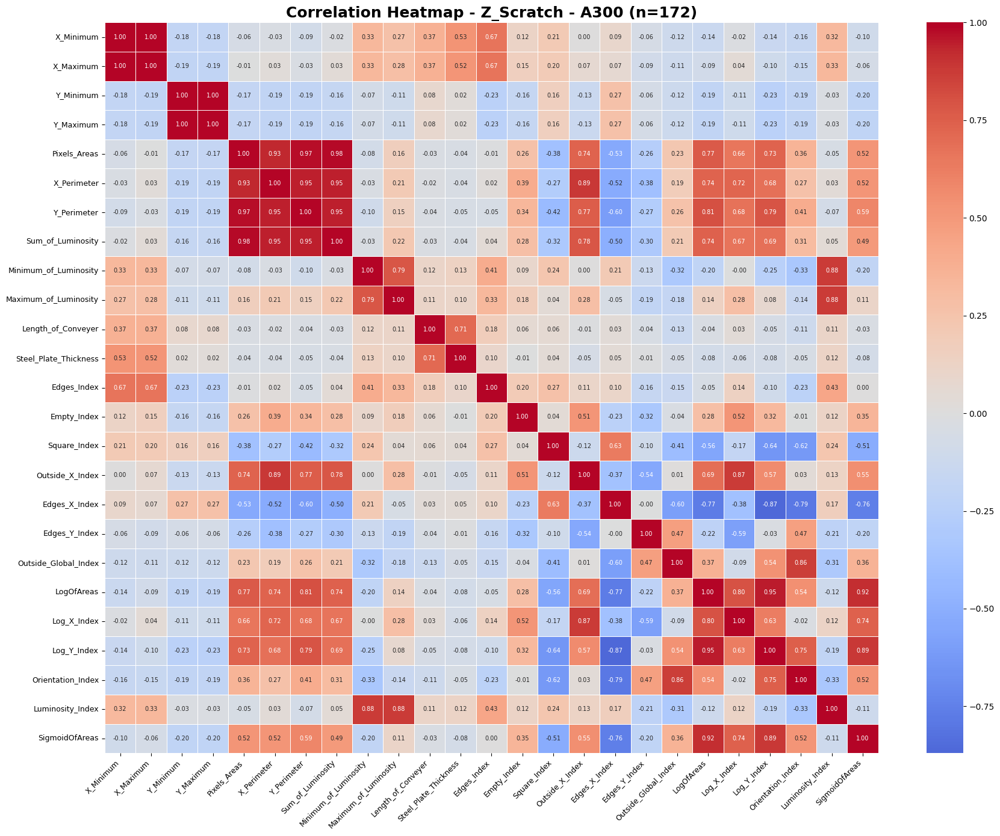


Highly correlated pairs (|r| > 0.8) - Z_Scratch - A300:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
0               X_Minimum          X_Maximum       0.9977
4            Pixels_Areas  Sum_of_Luminosity       0.9788
3            Pixels_Areas        Y_Perimeter       0.9741
15             LogOfAreas        Log_Y_Index       0.9525
6             X_Perimeter  Sum_of_Luminosity       0.9471
5             X_Perimeter        Y_Perimeter       0.9467
8             Y_Perimeter  Sum_of_Luminosity       0.9459
2            Pixels_Areas        X_Perimeter       0.9272
16             LogOfAreas     SigmoidOfAreas       0.9188
7             X_Perimeter    Outside_X_Index       0.8869
17            Log_Y_Index     SigmoidOfAreas       0.8867
10  Minimum_of_Luminosity   Luminosity_Index       0.8793
11  Maximum_of_Luminosity   Luminosity_Index       0.8762
12        Outside_X_Index        Log_X_Index       0.8745
14   Outside_Gl

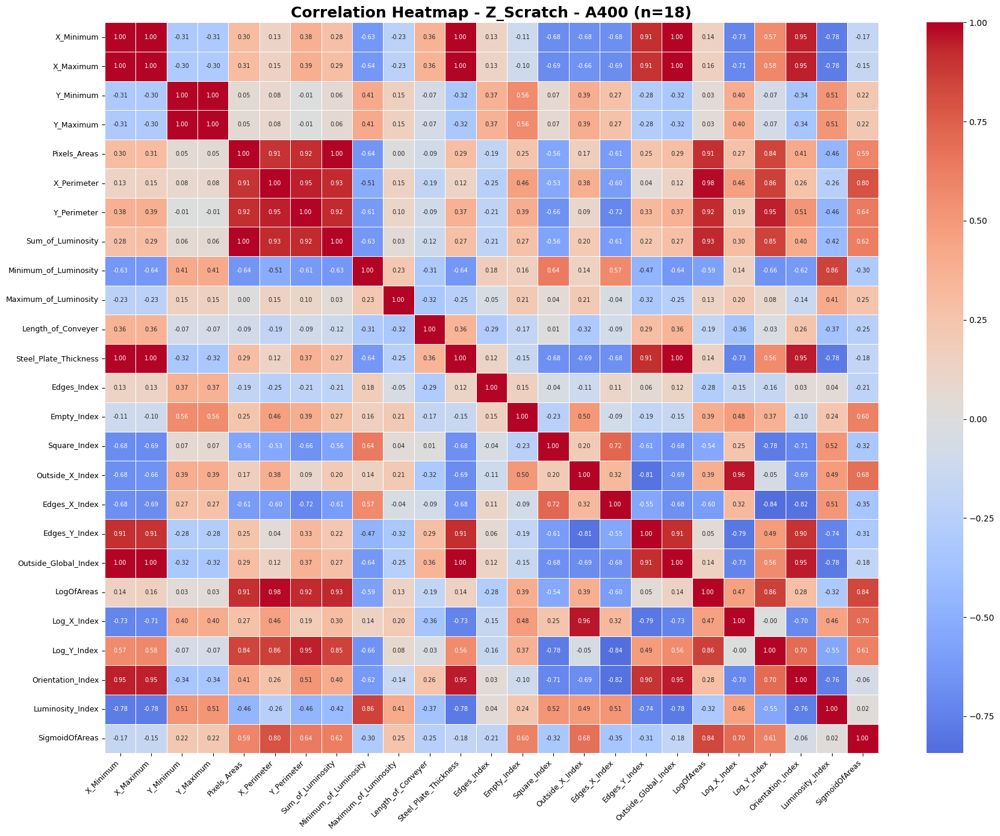


Highly correlated pairs (|r| > 0.8) - Z_Scratch - A400:
                Feature 1              Feature 2  Correlation
9               Y_Minimum              Y_Maximum       1.0000
26  Steel_Plate_Thickness   Outside_Global_Index       1.0000
0               X_Minimum              X_Maximum       0.9998
1               X_Minimum  Steel_Plate_Thickness       0.9978
3               X_Minimum   Outside_Global_Index       0.9978
7               X_Maximum   Outside_Global_Index       0.9974
5               X_Maximum  Steel_Plate_Thickness       0.9974
12           Pixels_Areas      Sum_of_Luminosity       0.9973
17            X_Perimeter             LogOfAreas       0.9797
29        Outside_X_Index            Log_X_Index       0.9588
34   Outside_Global_Index      Orientation_Index       0.9516
27  Steel_Plate_Thickness      Orientation_Index       0.9516
4               X_Minimum      Orientation_Index       0.9494
21            Y_Perimeter            Log_Y_Index       0.9489
8            

In [17]:
#define correlation parameters excluding steel type binary columns
corr_params = [p for p in params if p not in 
               ['TypeOfSteel_A300', 'TypeOfSteel_A400']]

#function to plot correlation heatmap
def plot_corr_heatmap(data, label):
    corr_matrix = data[corr_params].corr().round(4)
    plt.figure(figsize=(18, 14))
    sns.heatmap(corr_matrix, annot=True, fmt='.2f',
                cmap='coolwarm', center=0,
                linewidths=0.5, annot_kws={'size': 7})
    plt.title(f'Correlation Heatmap - {label} (n={len(data)})',
              fontsize=18, fontweight='bold')
    
    #slant x axis labels for easier reading
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(fontsize=9)
    
    plt.tight_layout()
    
    #save figure as png
    plt.savefig(f'Correlation_Heatmap_{label}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    return corr_matrix

#function to print highly correlated pairs
def get_high_corr(corr_matrix, label, threshold=0.8):
    high_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i,j]) > threshold:
                high_corr.append({
                    'Feature 1': corr_matrix.columns[i],
                    'Feature 2': corr_matrix.columns[j],
                    'Correlation': corr_matrix.iloc[i,j]
                })
    if len(high_corr) == 0:
        print(f"\nNo highly correlated pairs found - {label}")
        return pd.DataFrame()
    df_high = pd.DataFrame(high_corr).sort_values(
        'Correlation', ascending=False)
    print(f"\nHighly correlated pairs (|r| > {threshold}) - {label}:")
    print("="*60)
    print(df_high.to_string())
    return df_high

#section 1 - heatmaps for each fault class
print("="*60)
print("SECTION 1 - CORRELATION BY FAULT CLASS")
print("="*60)
for data, label in [(df_other, 'Other_Faults'),
                    (df_k, 'K_Scatch'),
                    (df_z, 'Z_Scratch')]:
    corr = plot_corr_heatmap(data, label)
    get_high_corr(corr, label)

#section 2 - heatmaps split by steel type
print("="*60)
print("SECTION 2 - CORRELATION BY FAULT CLASS AND STEEL TYPE")
print("="*60)
min_samples = 10
for data, fault_label in [(df_other, 'Other_Faults'),
                          (df_k, 'K_Scatch'),
                          (df_z, 'Z_Scratch')]:
    for steel in ['A300', 'A400']:
        subset = data[data['SteelType'] == steel]
        if len(subset) < min_samples:
            print(f"\nSkipping {fault_label} - {steel}: only {len(subset)} samples")
            continue
        corr = plot_corr_heatmap(subset, f'{fault_label} - {steel}')
        get_high_corr(corr, f'{fault_label} - {steel}')

In [22]:
#correlation cannot be calcualted for K_Scratch A300 as it only has one sample
#print sample counts for each fault class and steel type
print("Sample counts by Fault Class and Steel Type:")
print("="*60)
for data, label in [(df_other, 'Other_Faults'),
                    (df_k, 'K_Scatch'),
                    (df_z, 'Z_Scratch')]:
    print(f"\n{label}:")
    print(data['SteelType'].value_counts())
    
#The sample distribution is unbalanced across fault classes and steel types.
#K_Scratch contains only 1 A300 sample, making statistical analysis impossible for this combination.
#Z_Scratch A400 has only 18 samples which may produce unreliable correlation results.
#These imbalances should be considered when interpreting the findings,
# as conclusions drawn from small samples may not accurately represent the true population characteristics.

Sample counts by Fault Class and Steel Type:

Other_Faults:
SteelType
A400    407
A300    266
Name: count, dtype: int64

K_Scatch:
SteelType
A400    390
A300      1
Name: count, dtype: int64

Z_Scratch:
SteelType
A300    172
A400     18
Name: count, dtype: int64


SECTION 3 - CORRELATION BY STEEL TYPE (ALL FAULTS)

A300 - Total samples: 439


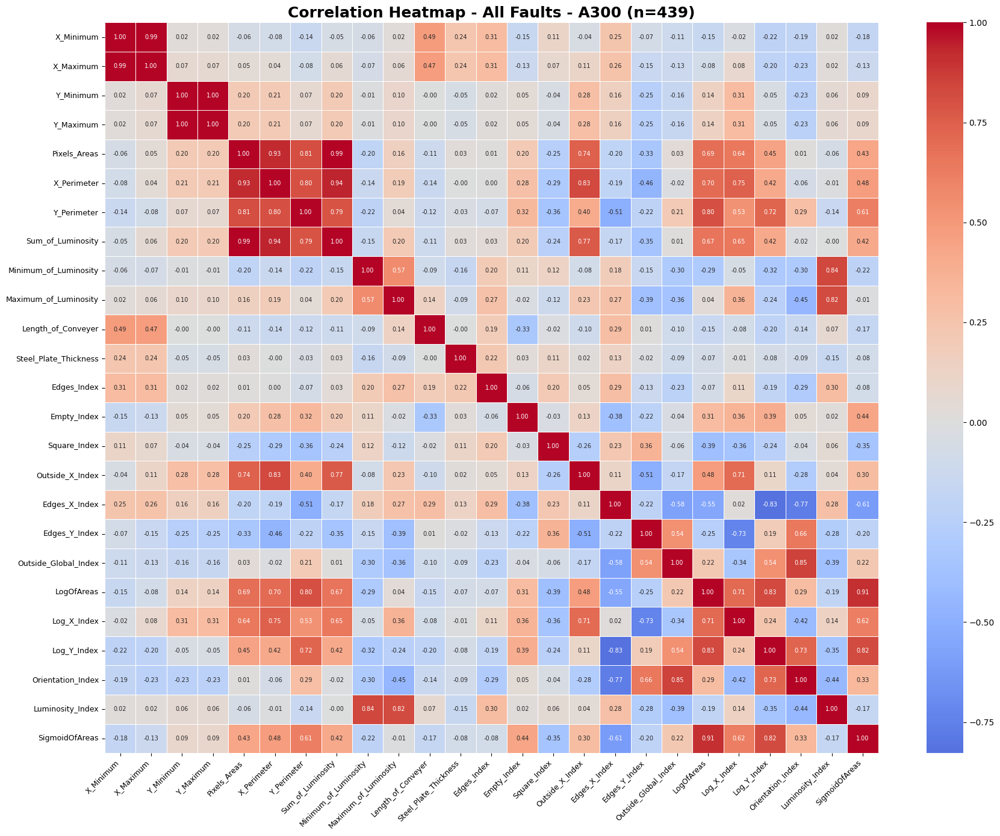


Highly correlated pairs (|r| > 0.8) - All Faults - A300:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
4            Pixels_Areas  Sum_of_Luminosity       0.9930
0               X_Minimum          X_Maximum       0.9888
6             X_Perimeter  Sum_of_Luminosity       0.9364
2            Pixels_Areas        X_Perimeter       0.9273
14             LogOfAreas     SigmoidOfAreas       0.9096
12   Outside_Global_Index  Orientation_Index       0.8538
9   Minimum_of_Luminosity   Luminosity_Index       0.8405
13             LogOfAreas        Log_Y_Index       0.8317
7             X_Perimeter    Outside_X_Index       0.8314
15            Log_Y_Index     SigmoidOfAreas       0.8205
10  Maximum_of_Luminosity   Luminosity_Index       0.8197
3            Pixels_Areas        Y_Perimeter       0.8133
8             Y_Perimeter         LogOfAreas       0.8030
5             X_Perimeter        Y_Perimeter       0.8023
11          Ed

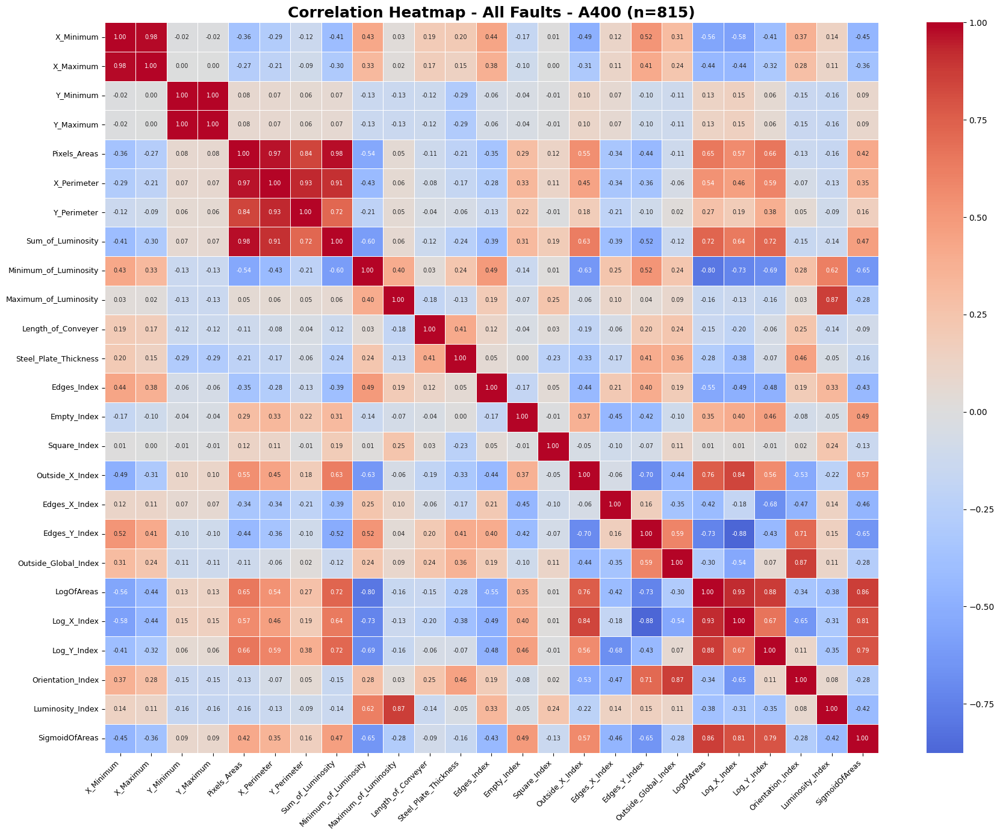


Highly correlated pairs (|r| > 0.8) - All Faults - A400:
                Feature 1          Feature 2  Correlation
1               Y_Minimum          Y_Maximum       1.0000
0               X_Minimum          X_Maximum       0.9808
4            Pixels_Areas  Sum_of_Luminosity       0.9766
2            Pixels_Areas        X_Perimeter       0.9675
5             X_Perimeter        Y_Perimeter       0.9292
12             LogOfAreas        Log_X_Index       0.9266
6             X_Perimeter  Sum_of_Luminosity       0.9079
13             LogOfAreas        Log_Y_Index       0.8799
8   Maximum_of_Luminosity   Luminosity_Index       0.8742
11   Outside_Global_Index  Orientation_Index       0.8741
14             LogOfAreas     SigmoidOfAreas       0.8618
3            Pixels_Areas        Y_Perimeter       0.8430
9         Outside_X_Index        Log_X_Index       0.8426
15            Log_X_Index     SigmoidOfAreas       0.8055
7   Minimum_of_Luminosity         LogOfAreas      -0.8023
10          Ed

In [23]:
#section 3 - correlation by steel type across all faults
print("="*60)
print("SECTION 3 - CORRELATION BY STEEL TYPE (ALL FAULTS)")
print("="*60)

for steel in ['A300', 'A400']:
    subset = df[df['SteelType'] == steel]
    print(f"\n{steel} - Total samples: {len(subset)}")
    corr = plot_corr_heatmap(subset, f'All Faults - {steel}')
    get_high_corr(corr, f'All Faults - {steel}')

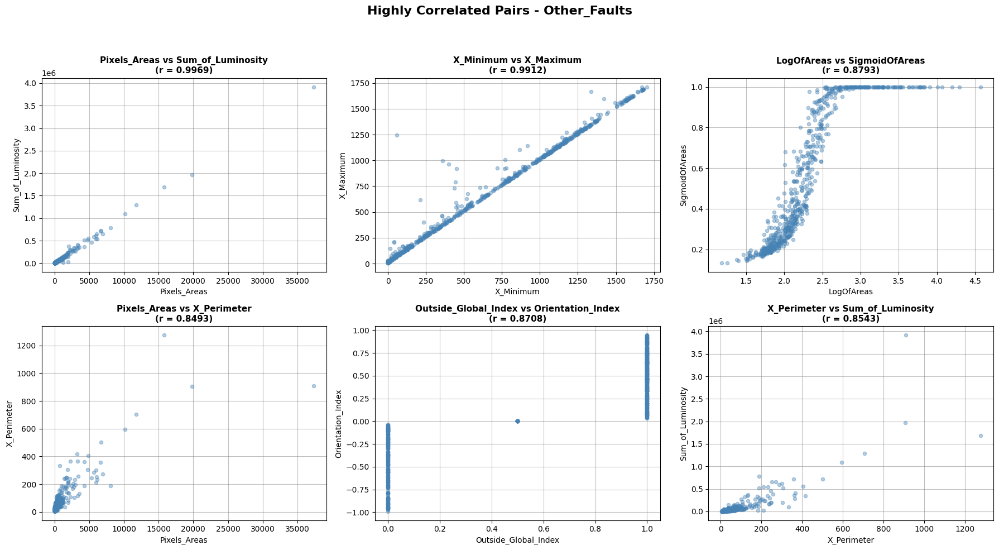

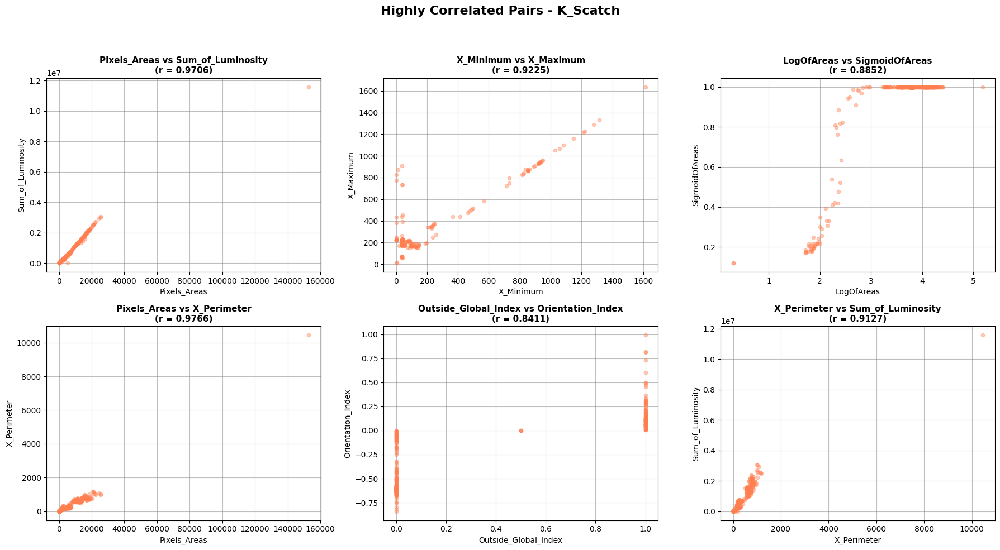

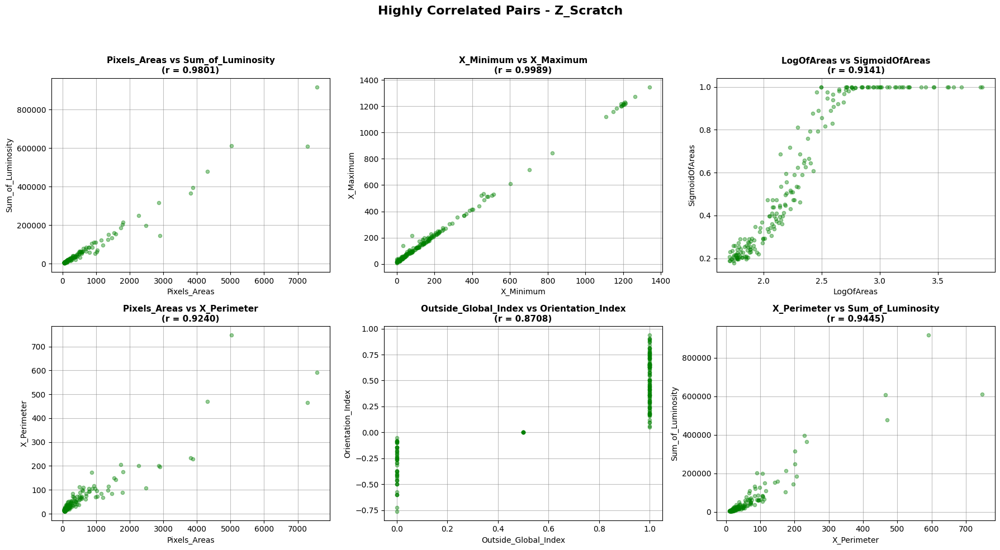

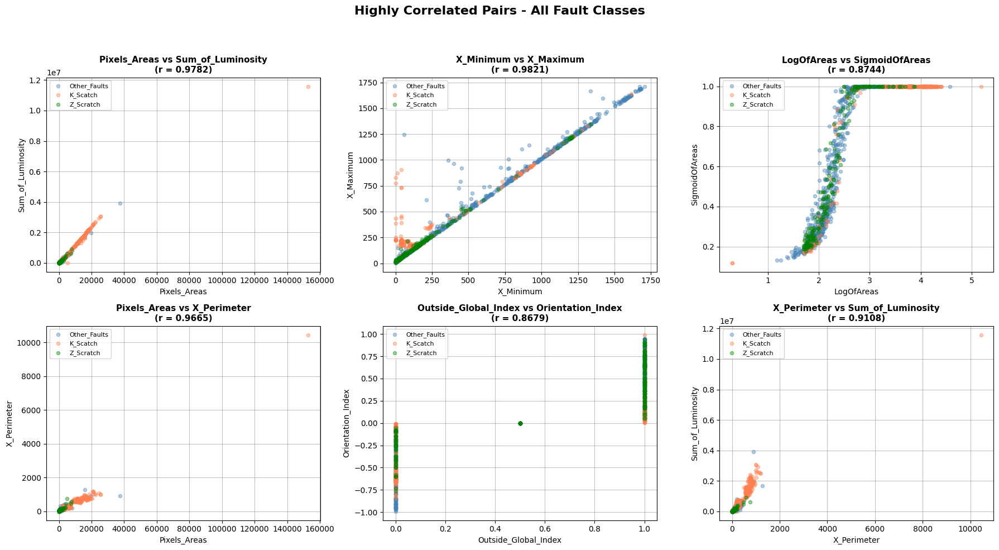

In [24]:
#highly correlated pairs identified earlier
high_corr_pairs = [
    ('Pixels_Areas', 'Sum_of_Luminosity'),
    ('X_Minimum', 'X_Maximum'),
    ('LogOfAreas', 'SigmoidOfAreas'),
    ('Pixels_Areas', 'X_Perimeter'),
    ('Outside_Global_Index', 'Orientation_Index'),
    ('X_Perimeter', 'Sum_of_Luminosity')
]

#function to plot scatter plots for highly correlated pairs
def plot_scatter_pairs(data, label, pairs, color='steelblue'):
    n_pairs = len(pairs)
    n_rows = (n_pairs + 2) // 3
    
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, n_rows * 5))
    axes = axes.flatten()
    
    for i, (x, y) in enumerate(pairs):
        axes[i].scatter(data[x], data[y], 
                        alpha=0.4, color=color, s=20)
        
        #add correlation value
        corr_val = data[x].corr(data[y])
        axes[i].set_title(f'{x} vs {y}\n(r = {corr_val:.4f})',
                          fontsize=11, fontweight='bold')
        axes[i].set_xlabel(x, fontsize=10)
        axes[i].set_ylabel(y, fontsize=10)
        
        #add grid lines
        axes[i].yaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
        axes[i].xaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
        axes[i].set_axisbelow(True)
    
    #hide empty subplots
    for j in range(n_pairs, len(axes)):
        axes[j].set_visible(False)
    
    plt.suptitle(f'Highly Correlated Pairs - {label}',
                 fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.94])   #leave top 6% for the main title
    
    #save figure as png
    plt.savefig(f'ScatterPlots_{label}.png', dpi=300, bbox_inches='tight')
    plt.show()

#plot scatter plots for each fault class
plot_scatter_pairs(df_other, 'Other_Faults', high_corr_pairs, color='steelblue')
plot_scatter_pairs(df_k, 'K_Scatch', high_corr_pairs, color='coral')
plot_scatter_pairs(df_z, 'Z_Scratch', high_corr_pairs, color='green')

#plot all fault classes together with different colours
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (x, y) in enumerate(high_corr_pairs):
    for fault, color in [('Other_Faults', 'steelblue'),
                         ('K_Scatch', 'coral'),
                         ('Z_Scratch', 'green')]:
        subset = df[df['Faults'] == fault]
        axes[i].scatter(subset[x], subset[y],
                        alpha=0.4, color=color, s=20, label=fault)
    
    corr_val = df[x].corr(df[y])
    axes[i].set_title(f'{x} vs {y}\n(r = {corr_val:.4f})',
                      fontsize=11, fontweight='bold')
    axes[i].set_xlabel(x, fontsize=10)
    axes[i].set_ylabel(y, fontsize=10)
    axes[i].legend(fontsize=8)
    axes[i].yaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
    axes[i].xaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
    axes[i].set_axisbelow(True)

plt.suptitle('Highly Correlated Pairs - All Fault Classes',
             fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])   #leave top 6% for the main title
plt.savefig('ScatterPlots_All_Fault_Classes.png', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
#function to compare A300 vs A400 for a given fault class
def compare_steel_types(df_fault, label):
    a300 = df_fault[df_fault['SteelType'] == 'A300']
    a400 = df_fault[df_fault['SteelType'] == 'A400']
    
    #skip if either steel type has too few samples
    if len(a300) < 10 or len(a400) < 10:
        print(f"\nSkipping {label} - insufficient samples (A300: {len(a300)}, A400: {len(a400)})")
        return
    
    compare = pd.DataFrame({
        'A300_Mean': a300[params].mean(),
        'A400_Mean': a400[params].mean(),
        'A300_Median': a300[params].median(),
        'A400_Median': a400[params].median(),
        'A300_Std': a300[params].std(),
        'A400_Std': a400[params].std(),
    })
    
    #difference in mean and percentage
    compare['Mean_Diff'] = compare['A400_Mean'] - compare['A300_Mean']
    compare['Diff_%'] = (compare['Mean_Diff']
                         / compare['A300_Mean'].abs().replace(0, np.nan) * 100)
    
    compare = compare.round(4).sort_values('Diff_%', key=lambda s: s.abs(),
                                           ascending=False)
    print(f"\nA300 vs A400 - {label}")
    display(compare)

#compare steel types for each fault class
compare_steel_types(df_other, 'Other_Faults')
compare_steel_types(df_k, 'K_Scatch')
compare_steel_types(df_z, 'Z_Scratch')


A300 vs A400 - Other_Faults


,A300_Mean,A400_Mean,A300_Median,A400_Median,A300_Std,A400_Std,Mean_Diff,Diff_%
Orientation_Index,-0.0448,0.2163,0.0000,0.3529,0.5204,0.5118,0.2610,583.2862
TypeOfSteel_A300,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,-1.0000,-100.0000
Luminosity_Index,-0.1758,-0.0889,-0.1540,-0.1014,0.1579,0.1645,0.0869,49.4220
Outside_Global_Index,0.4793,0.6806,0.5000,1.0000,0.4862,0.4561,0.2013,41.9897
Y_Perimeter,35.1278,49.5848,15.0000,27.0000,61.0097,74.0910,14.4569,41.1553
SigmoidOfAreas,0.4471,0.5972,0.2739,0.5659,0.3145,0.2999,0.1501,33.5707
Y_Minimum,1807254.6466,1208438.8256,1393485.5000,471955.0000,1479274.5279,2035636.2701,-598815.8211,-33.1340
Y_Maximum,1807280.6165,1208478.5602,1393500.5000,472005.0000,1479276.4544,2035634.0076,-598802.0563,-33.1328
Outside_X_Index,0.0243,0.0170,0.0089,0.0103,0.0734,0.0237,-0.0073,-30.0925
Edges_X_Index,0.7220,0.5790,0.7515,0.5789,0.2214,0.2428,-0.1430,-19.8083



Skipping K_Scatch - insufficient samples (A300: 1, A400: 390)

A300 vs A400 - Z_Scratch


,A300_Mean,A400_Mean,A300_Median,A400_Median,A300_Std,A400_Std,Mean_Diff,Diff_%
X_Minimum,155.0291,728.0556,82.5000,1149.5000,219.4789,534.0043,573.0265,369.6252
X_Maximum,173.3605,750.5556,103.5000,1159.5000,220.1116,523.9688,577.1951,332.9451
TypeOfSteel_A300,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,-1.0000,-100.0000
Luminosity_Index,-0.2033,-0.0708,-0.1750,-0.0490,0.1392,0.0774,0.1325,65.1634
Steel_Plate_Thickness,70.3488,115.0000,70.0000,175.0000,3.2255,69.0268,44.6512,63.4711
Y_Perimeter,47.3140,72.2222,21.0000,33.0000,72.5424,91.0356,24.9083,52.6447
Sum_of_Luminosity,49729.7849,68058.5556,15155.0000,20221.5000,110369.3028,100422.3107,18328.7707,36.8567
X_Perimeter,54.6512,73.8889,25.5000,43.5000,90.7997,66.1308,19.2377,35.2009
Square_Index,0.5802,0.4323,0.5882,0.4116,0.2404,0.2463,-0.1479,-25.4918
Y_Minimum,1339644.3721,1022720.6111,1317916.5000,1095230.5000,777530.0878,353289.9843,-316923.7610,-23.6573


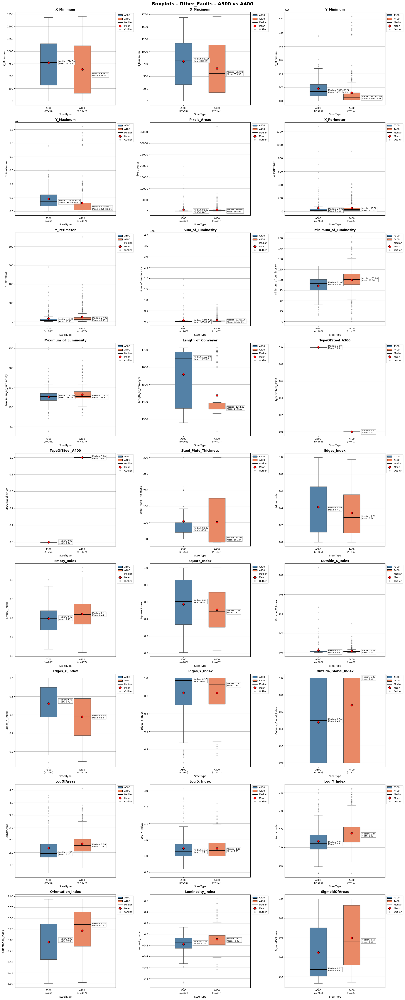

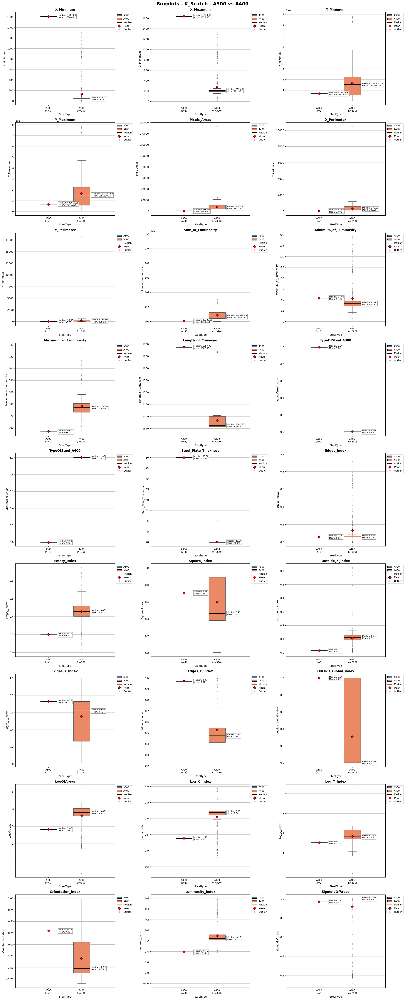

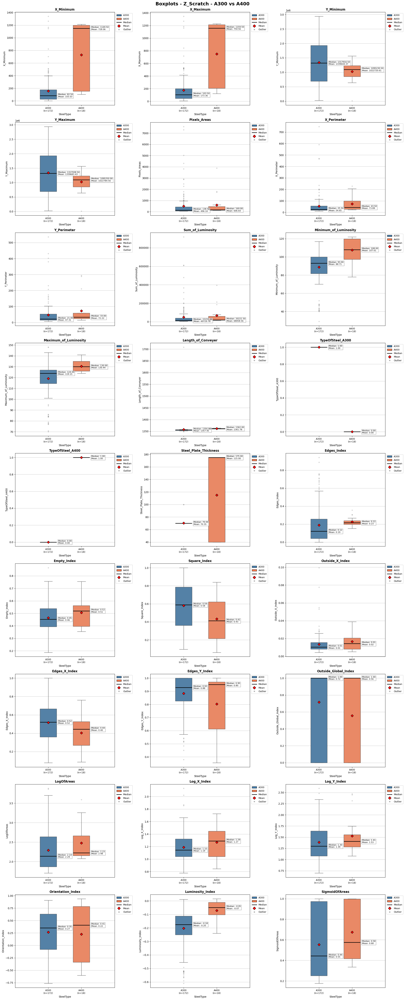

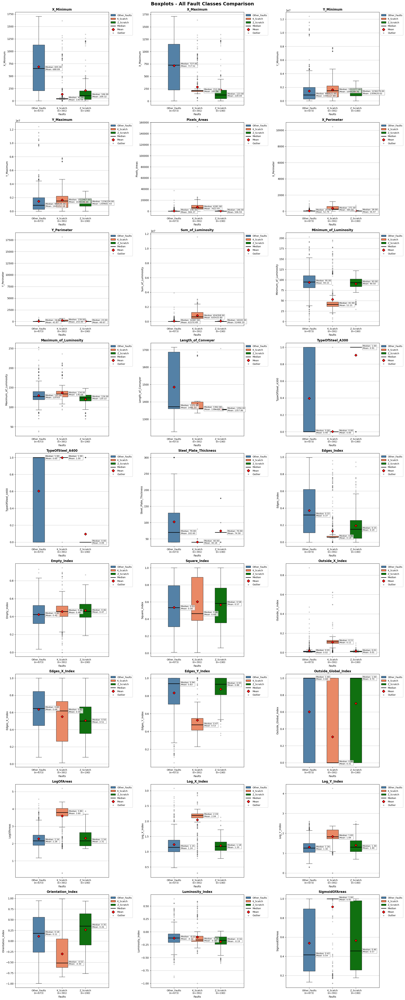

In [52]:
#function to write median and mean values next to each box
def add_box_values(ax, data, param, group_col, order):
    ymin, ymax = ax.get_ylim()
    for pos, group in enumerate(order):
        vals = data.loc[data[group_col] == group, param].dropna()
        if len(vals) == 0:
            continue
        med = vals.median()
        mean = vals.mean()
        if ymin <= med <= ymax:
            ax.text(pos + 0.3, med,
                    f'Median: {med:.2f}\nMean: {mean:.2f}',
                    ha='left', va='center', fontsize=8,
                    bbox=dict(facecolor='white', edgecolor='gray',
                              alpha=0.8, pad=2))
    ax.set_xlim(-1.0, len(order) - 1 + 1.0)

#function to plot boxplots for any grouping
def plot_boxplots(data, label, group_col, order, palette):
    #check sample sizes
    for group in order:
        n = (data[group_col] == group).sum()
        if n < 10:
            print(f"Warning: {group} has only {n} samples")

    #build x labels with sample counts
    xlabels = [f'{g}\n(n={(data[group_col]==g).sum()})' for g in order]

    #build legend
    legend_items = [
        Patch(facecolor=palette[g], edgecolor='black', label=g)
        for g in order
    ] + [
        Line2D([0], [0], color='black', linewidth=2, label='Median'),
        Line2D([0], [0], marker='D', color='w', markerfacecolor='red',
               markeredgecolor='black', markersize=8, label='Mean'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
               markersize=6, alpha=0.6, label='Outlier'),
    ]

    fig, axes = plt.subplots(9, 3, figsize=(22, 55))
    axes = axes.flatten()

    for i, param in enumerate(all_params):
        sns.boxplot(data=data, x=group_col, y=param,
                    order=order, hue=group_col, hue_order=order,
                    palette=palette, legend=False,
                    width=0.5,
                    showmeans=True,
                    medianprops=dict(color='black', linewidth=2),
                    meanprops=dict(marker='D', markerfacecolor='red',
                                   markeredgecolor='black', markersize=7),
                    flierprops=dict(marker='o', markersize=3, alpha=0.4),
                    ax=axes[i])
        add_box_values(axes[i], data, param, group_col, order)
        axes[i].set_title(param, fontsize=12, fontweight='bold')
        axes[i].set_xticks(range(len(order)))
        axes[i].set_xticklabels(xlabels, fontsize=9)
        axes[i].set_xlabel(group_col, fontsize=10)
        axes[i].set_ylabel(param, fontsize=10)
        axes[i].legend(handles=legend_items, loc='upper left',
                       bbox_to_anchor=(1, 1), fontsize=9)
        
        #add horizontal grid lines on y axis
        axes[i].yaxis.grid(True, linestyle='-', alpha=0.5, color='gray')
        axes[i].set_axisbelow(True)

    for j in range(len(all_params), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Boxplots - {label}', fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.97)
    plt.savefig(f'Boxplots_{label}.png', dpi=300, bbox_inches='tight')
    plt.show()

#plot A300 vs A400 for each fault class
plot_boxplots(df_other, 'Other_Faults - A300 vs A400',
              group_col='SteelType', order=['A300', 'A400'],
              palette={'A300': 'steelblue', 'A400': 'coral'})

plot_boxplots(df_k, 'K_Scatch - A300 vs A400',
              group_col='SteelType', order=['A300', 'A400'],
              palette={'A300': 'steelblue', 'A400': 'coral'})

plot_boxplots(df_z, 'Z_Scratch - A300 vs A400',
              group_col='SteelType', order=['A300', 'A400'],
              palette={'A300': 'steelblue', 'A400': 'coral'})

#plot all 3 fault classes together
plot_boxplots(df, 'All Fault Classes Comparison',
              group_col='Faults',
              order=['Other_Faults', 'K_Scatch', 'Z_Scratch'],
              palette={'Other_Faults': 'steelblue',
                       'K_Scatch': 'coral',
                       'Z_Scratch': 'green'})

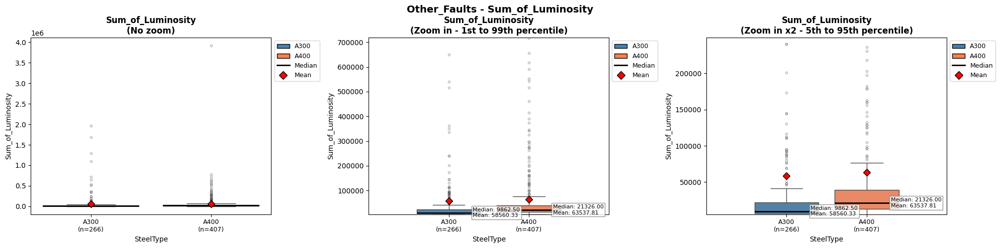

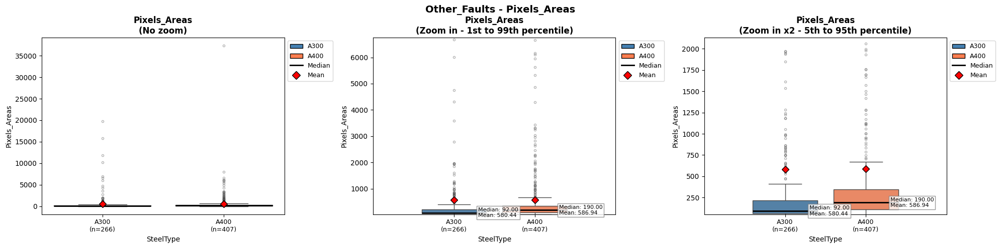

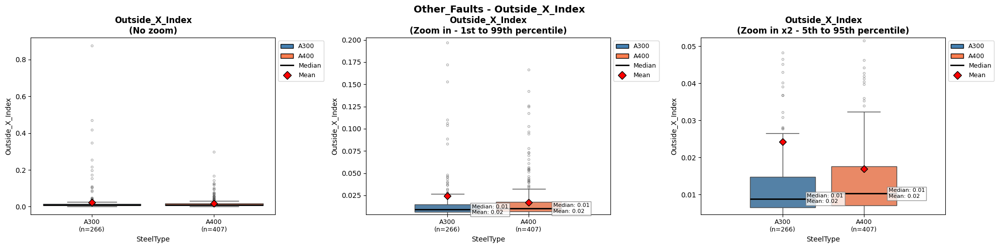

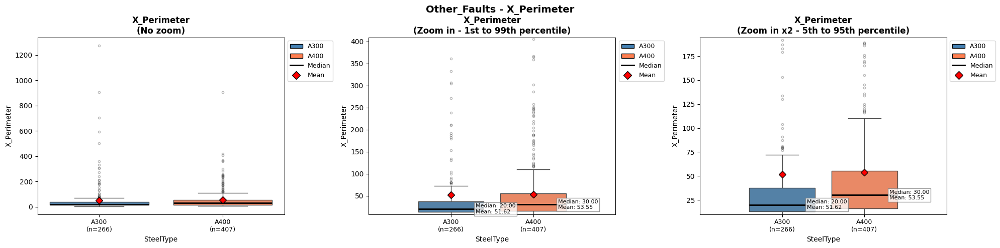

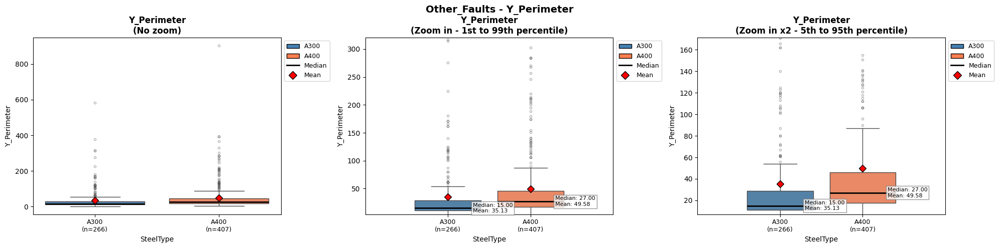

...

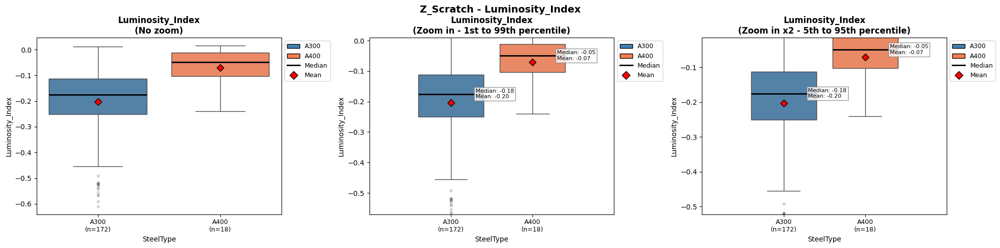

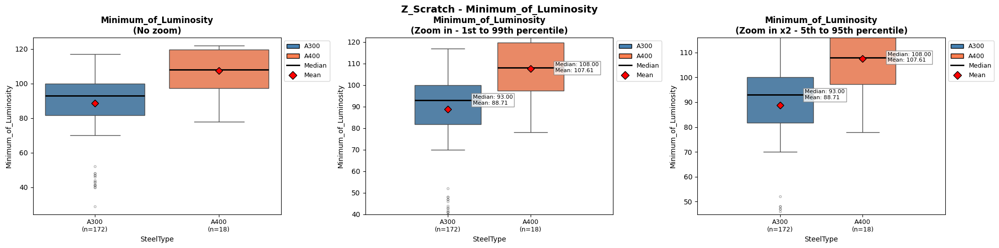

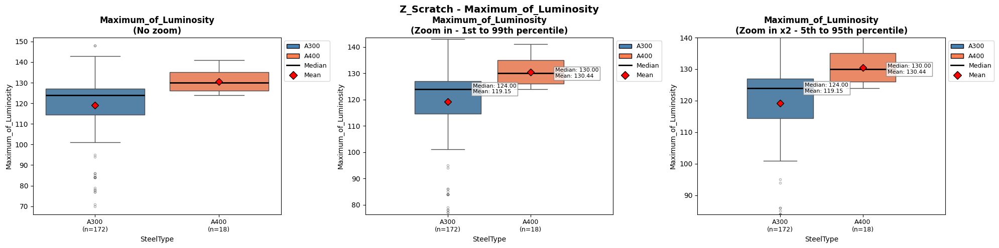

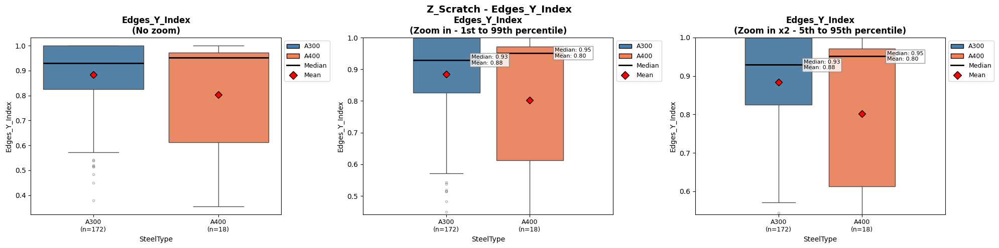

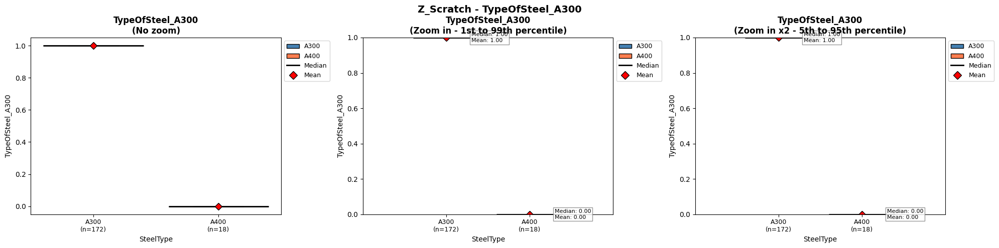

In [53]:
#function to plot 3 levels of zoom for skewed parameters
def plot_zoom_levels(data, label, skewed_params_list, group_col, order, palette):
    
    legend_items = [
        Patch(facecolor=palette[g], edgecolor='black', label=g)
        for g in order
    ] + [
        Line2D([0], [0], color='black', linewidth=2, label='Median'),
        Line2D([0], [0], marker='D', color='w', markerfacecolor='red',
               markeredgecolor='black', markersize=8, label='Mean'),
    ]
    
    xlabels = [f'{g}\n(n={(data[group_col]==g).sum()})' for g in order]
    
    for param in skewed_params_list:
        
        #3 columns: no zoom, zoom in, zoom in x2
        fig, axes = plt.subplots(1, 3, figsize=(20, 5))
        
        for ax in axes:
            sns.boxplot(data=data, x=group_col, y=param,
                        order=order, hue=group_col, hue_order=order,
                        palette=palette, legend=False,
                        showmeans=True,
                        medianprops=dict(color='black', linewidth=2),
                        meanprops=dict(marker='D', markerfacecolor='red',
                                       markeredgecolor='black', markersize=7),
                        flierprops=dict(marker='o', markersize=3, alpha=0.4),
                        ax=ax)
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels(xlabels, fontsize=9)
            ax.set_xlabel(group_col, fontsize=10)
            ax.set_ylabel(param, fontsize=10)
            ax.legend(handles=legend_items, loc='upper left',
                      bbox_to_anchor=(1, 1), fontsize=9)
        
        #no zoom
        axes[0].set_title(f'{param}\n(No zoom)', 
                          fontsize=12, fontweight='bold')
        
        #zoom in - 1st to 99th percentile
        q01 = data[param].quantile(0.01)
        q99 = data[param].quantile(0.99)
        if q99 > q01:
            axes[1].set_ylim(q01, q99)
        else:
            axes[1].set_ylim(data[param].min() - 0.1,
                             data[param].max() + 0.1)
        axes[1].set_title(f'{param}\n(Zoom in - 1st to 99th percentile)', 
                          fontsize=12, fontweight='bold')
        add_box_values(axes[1], data, param, group_col, order)
        
        #zoom in x2 - 5th to 95th percentile
        q05 = data[param].quantile(0.05)
        q95 = data[param].quantile(0.95)
        if q95 > q05:
            axes[2].set_ylim(q05, q95)
        else:
            axes[2].set_ylim(data[param].min() - 0.1,
                             data[param].max() + 0.1)
        axes[2].set_title(f'{param}\n(Zoom in x2 - 5th to 95th percentile)', 
                          fontsize=12, fontweight='bold')
        add_box_values(axes[2], data, param, group_col, order)
        
        plt.suptitle(f'{label} - {param}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.savefig(f'ZoomBoxplot_{label}_{param}.png', 
                    dpi=300, bbox_inches='tight')
        plt.show()

#plot zoom levels for each fault class
plot_zoom_levels(df_other, 'Other_Faults', skewed_other,
                 group_col='SteelType', order=['A300', 'A400'],
                 palette={'A300': 'steelblue', 'A400': 'coral'})

plot_zoom_levels(df_k, 'K_Scatch', skewed_k,
                 group_col='SteelType', order=['A300', 'A400'],
                 palette={'A300': 'steelblue', 'A400': 'coral'})

plot_zoom_levels(df_z, 'Z_Scratch', skewed_z,
                 group_col='SteelType', order=['A300', 'A400'],
                 palette={'A300': 'steelblue', 'A400': 'coral'})

In [56]:
import zipfile
import os

#create zip file of all png files in the same folder as this notebook
with zipfile.ZipFile('all_plots.zip', 'w') as zipf:
    for file in os.listdir('.'):
        if file.endswith('.png'):
            zipf.write(file, file)
            print(f'Added: {file}')

print("\nZip file created: all_plots.zip")
print(f"Total size: {os.path.getsize('all_plots.zip') / 1024 / 1024:.1f} MB")

Added: Correlation_Heatmap_Other_Faults - A400.png
Added: ZoomBoxplot_K_Scatch_Y_Maximum.png
Added: ZoomBoxplot_K_Scatch_Minimum_of_Luminosity.png
Added: ZoomBoxplot_K_Scatch_Y_Minimum.png
Added: ZoomBoxplot_Z_Scratch_Sum_of_Luminosity.png
Added: Boxplots_Z_Scratch - A300 vs A400.png
Added: ZoomBoxplot_Z_Scratch_Length_of_Conveyer.png
Added: ZoomBoxplot_Z_Scratch_X_Maximum.png
Added: Correlation_Heatmap_Other_Faults.png
Added: Histograms_K_Scatch.png
Added: ZoomBoxplot_Other_Faults_Y_Maximum.png
Added: ZoomBoxplot_K_Scatch_Y_Perimeter.png
Added: ZoomBoxplot_Z_Scratch_Minimum_of_Luminosity.png
Added: ZoomBoxplot_K_Scatch_TypeOfSteel_A300.png
Added: ZoomBoxplot_K_Scatch_Outside_X_Index.png
Added: Correlation_Heatmap_Z_Scratch - A300.png
Added: ZoomBoxplot_Z_Scratch_Edges_Y_Index.png
Added: ZoomBoxplot_K_Scatch_Maximum_of_Luminosity.png
Added: Boxplots_K_Scatch - A300 vs A400.png
Added: Correlation_Heatmap_Other_Faults - A300.png
Added: ZoomBoxplot_K_Scatch_SigmoidOfAreas.png
Added: ZoomB